# Heart Disease Prediction — Machine Learning Project
**CA-4 Use Case Based Continuous Assessment — Classification Case Study**

## Project Objective
The objective is to **predict whether a patient has heart disease** (`HeartDisease` = 1) or not (= 0) from routine clinical measurements: age, sex, chest-pain type, resting blood pressure, cholesterol, fasting blood sugar, resting ECG, maximum heart rate, exercise-induced angina, ST depression (`Oldpeak`) and ST-slope. An early, data-driven risk flag can help doctors decide which patients need further tests first.

## Project Workflow (as required by the CA-4 document)
| Week | Activities |
|---|---|
| Week 1 | Problem understanding, data download, EDA (missing values, outliers, distributions, correlation), feature encoding, 70:30 split |
| Week 1 (Baseline) | Logistic Regression, Decision Tree, KNN — accuracy, precision, recall, F1, ROC-AUC, confusion matrix, comparison table, interpretation |
| Week 2 | Random Forest, Gradient Boosting / XGBoost, GridSearchCV, cross-validation, ROC curves, error analysis, feature importance |
| Week 4 | Final model justification, feature-importance explanation, clinical insights, limitations, future improvements, optional Streamlit demo |

## Methodology
- Target variable: `HeartDisease` (0 = no disease, 1 = heart disease)
- Problem type: **Supervised Binary Classification**
- Train-test split: **70 % train / 30 % test**, *stratified* so both parts keep the same class ratio
- Evaluation metrics: **Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrix**
- Validation: **5-fold stratified cross-validation** (on the training data only)
- Hyper-parameter tuning: **GridSearchCV** (scored by ROC-AUC)
- The **test set is used only once**, for the final evaluation. Model selection is done with cross-validation.

> **How to use this notebook:** run *Runtime → Run all*. At the very end it builds two Word reports (Technical Report and EDA Report) with your real tables, figures and numbers, and zips everything for download. Fill in your name and PRN in the settings cell first.

---
# WEEK 1 — Problem Understanding & Data Exploration

## 1.1 Business / scientific problem
Heart disease is one of the leading causes of death worldwide. Hospitals collect cheap and quick measurements (blood pressure, cholesterol, ECG, exercise test) from every patient, but deciding who needs an expensive follow-up (angiography, stress imaging) is difficult. A classification model that estimates the probability of heart disease can act as a **screening aid** that helps doctors prioritise patients. It does **not** replace a diagnosis.

* **Problem type:** supervised **binary classification** (the target is 0 / 1).
* **Target variable:** `HeartDisease`.
* **Why regression is not used:** the target is a class label, not a continuous number, so regression metrics (MAE, RMSE, R²) are *not applicable*.
* **Most important error type:** a **false negative** (a sick patient predicted healthy) is more harmful than a false positive, so **recall** is examined carefully together with precision, F1 and ROC-AUC.

## 1.2 Dataset source (official)
**Heart Failure Prediction Dataset** — Kaggle dataset by *fedesoriano* (`fedesoriano/heart-failure-prediction`), https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction. It combines five public heart-disease datasets (UCI) with 11 common features.

| Column | Meaning |
|---|---|
| `Age` | age of the patient (years) |
| `Sex` | M = male, F = female |
| `ChestPainType` | TA = typical angina, ATA = atypical angina, NAP = non-anginal pain, ASY = asymptomatic |
| `RestingBP` | resting blood pressure (mm Hg) |
| `Cholesterol` | serum cholesterol (mg/dl) |
| `FastingBS` | fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) |
| `RestingECG` | resting ECG result: Normal, ST (ST-T wave abnormality), LVH (left ventricular hypertrophy) |
| `MaxHR` | maximum heart rate achieved |
| `ExerciseAngina` | exercise-induced angina (Y / N) |
| `Oldpeak` | ST depression induced by exercise (numeric) |
| `ST_Slope` | slope of the peak-exercise ST segment: Up, Flat, Down |
| `HeartDisease` | **target** — 1 = heart disease, 0 = normal |

In [ ]:
!pip install -q xgboost kagglehub scipy python-docx

In [ ]:
# ---------------------------------------------------------------
# Imports, global settings and helper functions
# ---------------------------------------------------------------
import os, glob, json, random, textwrap, warnings, zipfile
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report, ConfusionMatrixDisplay)
import joblib

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False
    print("XGBoost is not installed - it will be skipped (run the pip cell above to install it).")

# ====== EDIT THESE FOUR LINES (they appear on the report title page) ======
STUDENT_NAME = "Amkanti srishanth"
PRN          = "24070724002"
COURSE       = "Supervised Machine Learning"
INSTITUTE    = "Symbiosis Institute of Technology, Hyderabad"
# ==========================================================================

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
sns.set_theme(style="whitegrid")

FIG_DIR = "figures"
REPORT_DIR = "reports"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

notes = {}   # every auto-written interpretation is stored here and reused in the Word reports

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

def say(key, text, width=110):
    # Print a wrapped paragraph and keep it for the report.
    notes[key] = text
    print(textwrap.fill(text, width=width))

print("All libraries imported successfully!  XGBoost available:", HAS_XGB)

All libraries imported successfully!  XGBoost available: True


In [ ]:
# ---------------------------------------------------------------
# Locate / download the dataset
#   1) already uploaded to Colab (or a local folder)
#   2) automatic download from the official Kaggle source (kagglehub)
#   3) manual upload through the Colab file picker
# ---------------------------------------------------------------
REQUIRED_COLUMNS = {"Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol", "FastingBS",
                    "RestingECG", "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope", "HeartDisease"}

def find_dataset_csv():
    folders = ["/content", "/content/data", "/data", "data", "/kaggle/input/heart-failure-prediction", "."]
    for folder in folders:
        for path in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True):
            try:
                if REQUIRED_COLUMNS.issubset(set(pd.read_csv(path, nrows=1).columns)):
                    return path
            except Exception:
                pass
    return None

DATA_FILE = find_dataset_csv()

if DATA_FILE is None:
    try:
        import kagglehub
        download_dir = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
        for path in glob.glob(os.path.join(download_dir, "**", "*.csv"), recursive=True):
            if REQUIRED_COLUMNS.issubset(set(pd.read_csv(path, nrows=1).columns)):
                DATA_FILE = path
                break
    except Exception as err:
        print("Automatic download was not possible:", err)

if DATA_FILE is None:
    try:
        from google.colab import files
        print("Please upload heart.csv (download it from the Kaggle link above).")
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded))
    except Exception:
        pass

if DATA_FILE is None:
    raise FileNotFoundError(
        "Dataset not found. Download heart.csv from "
        "https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction "
        "and upload it to /content (Colab: left sidebar -> Files -> upload)."
    )
print("Dataset file:", DATA_FILE)

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.
Dataset file: /kaggle/input/heart-failure-prediction/heart.csv


In [ ]:
# Load the dataset
raw = pd.read_csv(DATA_FILE)
raw = raw.drop(columns=[c for c in raw.columns if c.lower().startswith("unnamed")], errors="ignore")
data = raw.copy()

print("DATASET LOADED SUCCESSFULLY!")
print("Shape:", data.shape)
display(data.head())
print()
data.info()

DATASET LOADED SUCCESSFULLY!
Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


## 1.3 Dataset description — size, feature types and target variable

In [ ]:
TARGET      = "HeartDisease"
NUMERIC     = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
BINARY      = ["FastingBS"]
CATEGORICAL = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
FEATURES    = NUMERIC + BINARY + CATEGORICAL

feature_info = {
    "Age":            ("Numerical - continuous", "Feature", "Age of the patient (years)"),
    "Sex":            ("Categorical - nominal",  "Feature", "M = male, F = female"),
    "ChestPainType":  ("Categorical - nominal",  "Feature", "TA / ATA / NAP / ASY"),
    "RestingBP":      ("Numerical - continuous", "Feature", "Resting blood pressure (mm Hg)"),
    "Cholesterol":    ("Numerical - continuous", "Feature", "Serum cholesterol (mg/dl)"),
    "FastingBS":      ("Binary (0/1)",           "Feature", "Fasting blood sugar > 120 mg/dl"),
    "RestingECG":     ("Categorical - nominal",  "Feature", "Normal / ST / LVH"),
    "MaxHR":          ("Numerical - continuous", "Feature", "Maximum heart rate achieved"),
    "ExerciseAngina": ("Categorical - binary",   "Feature", "Exercise-induced angina (Y/N)"),
    "Oldpeak":        ("Numerical - continuous", "Feature", "ST depression induced by exercise"),
    "ST_Slope":       ("Categorical - ordinal",  "Feature", "Up / Flat / Down"),
    "HeartDisease":   ("Binary (0/1)",           "TARGET",  "1 = heart disease, 0 = normal"),
}

print("DATASET SIZE")
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])

feature_types = pd.DataFrame({
    "Column":       data.columns,
    "Data type":    [str(t) for t in data.dtypes],
    "Feature type": [feature_info.get(c, ("-", "-", "-"))[0] for c in data.columns],
    "Role":         [feature_info.get(c, ("-", "-", "-"))[1] for c in data.columns],
    "Description":  [feature_info.get(c, ("-", "-", "-"))[2] for c in data.columns],
})
print("\nFEATURE TYPES")
display(feature_types)

DATASET SIZE
Rows    : 918
Columns : 12

FEATURE TYPES


,Column,Data type,Feature type,Role,Description
0,Age,int64,Numerical - continuous,Feature,Age of the patient (years)
1,Sex,object,Categorical - nominal,Feature,"M = male, F = female"
2,ChestPainType,object,Categorical - nominal,Feature,TA / ATA / NAP / ASY
3,RestingBP,int64,Numerical - continuous,Feature,Resting blood pressure (mm Hg)
4,Cholesterol,int64,Numerical - continuous,Feature,Serum cholesterol (mg/dl)
5,FastingBS,int64,Binary (0/1),Feature,Fasting blood sugar > 120 mg/dl
6,RestingECG,object,Categorical - nominal,Feature,Normal / ST / LVH
7,MaxHR,int64,Numerical - continuous,Feature,Maximum heart rate achieved
8,ExerciseAngina,object,Categorical - binary,Feature,Exercise-induced angina (Y/N)
9,Oldpeak,float64,Numerical - continuous,Feature,ST depression induced by exercise


**Feature-type explanation**

* **Numerical continuous:** `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak` are real-valued measurements.
* **Binary:** `FastingBS` is already 0/1; the target `HeartDisease` is 0/1.
* **Categorical:** `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope` are text categories, so they need **encoding** (one-hot) before modelling.
* **Leakage check:** all eleven features are measured during the check-up *before* the diagnosis is known, so none of them leaks the target.

In [ ]:
# ---------------------------------------------------------------
# Data quality: missing values, impossible zeros, duplicates
# ---------------------------------------------------------------
print("MISSING VALUE ANALYSIS (as stored in the file)")
missing_raw = pd.DataFrame({
    "Missing values": data.isnull().sum(),
    "Missing %": (data.isnull().mean() * 100).round(3),
})
display(missing_raw)

# In this dataset missing cholesterol / blood pressure is stored as 0, which is physiologically impossible.
zero_chol = int((data["Cholesterol"] == 0).sum())
zero_bp   = int((data["RestingBP"] == 0).sum())
print(f"\nCholesterol recorded as 0 : {zero_chol} rows")
print(f"RestingBP recorded as 0   : {zero_bp} rows")

# Treat the impossible zeros as missing values (NaN). They are imputed later INSIDE the pipeline.
data.loc[data["Cholesterol"] == 0, "Cholesterol"] = np.nan
data.loc[data["RestingBP"] == 0, "RestingBP"] = np.nan

# Duplicates
n_raw = len(data)
n_dup = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
n_rows = len(data)
print(f"\nDuplicate rows removed: {n_dup}  ({n_raw} -> {n_rows} rows)")

missing_table = pd.DataFrame({
    "Missing values": data.isnull().sum(),
    "Missing %": (data.isnull().mean() * 100).round(2),
})
print("\nMISSING VALUES AFTER TREATING ZEROS AS MISSING")
display(missing_table[missing_table["Missing values"] > 0] if missing_table["Missing values"].sum() > 0 else missing_table)

say("missing",
    f"Interpretation (data quality): the file contains {int(missing_raw['Missing values'].sum())} cells marked as missing, but "
    f"{zero_chol} cholesterol values and {zero_bp} resting blood-pressure values are recorded as 0, which is physiologically impossible. "
    f"These zeros were treated as missing values (NaN), not as real measurements. They are filled with the training-set median inside the "
    f"modelling pipeline, so no test-set information leaks into training. {n_dup} duplicate row(s) were removed ({n_raw} to {n_rows} rows).")

MISSING VALUE ANALYSIS (as stored in the file)


,Missing values,Missing %
Age,0,0.0
Sex,0,0.0
ChestPainType,0,0.0
RestingBP,0,0.0
Cholesterol,0,0.0
FastingBS,0,0.0
RestingECG,0,0.0
MaxHR,0,0.0
ExerciseAngina,0,0.0
Oldpeak,0,0.0



Cholesterol recorded as 0 : 172 rows
RestingBP recorded as 0   : 1 rows

Duplicate rows removed: 0  (918 -> 918 rows)

MISSING VALUES AFTER TREATING ZEROS AS MISSING


,Missing values,Missing %
RestingBP,1,0.11
Cholesterol,172,18.74


Interpretation (data quality): the file contains 0 cells marked as missing, but 172 cholesterol values and 1
resting blood-pressure values are recorded as 0, which is physiologically impossible. These zeros were treated
as missing values (NaN), not as real measurements. They are filled with the training-set median inside the
modelling pipeline, so no test-set information leaks into training. 0 duplicate row(s) were removed (918 to
918 rows).


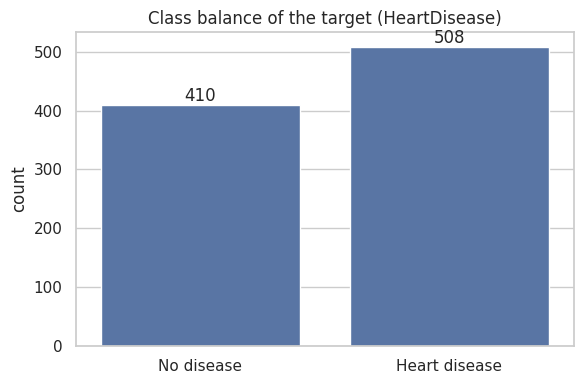

Interpretation (target): 508 patients (55.3%) have heart disease and 410 (44.7%) do not (ratio 1.24 : 1). The
classes are reasonably balanced, so resampling (SMOTE) or class weights are not needed and accuracy is a
meaningful metric, although recall, F1 and ROC-AUC are still reported because a missed patient (false
negative) is costly.

STATISTICAL DESCRIPTION (numeric features)


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,917.0,132.54,18.00,80.0,120.00,130.0,140.0,200.0
Cholesterol,746.0,244.64,59.15,85.0,207.25,237.0,275.0,603.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0


In [ ]:
# ---------------------------------------------------------------
# Target variable: class balance
# ---------------------------------------------------------------
label = data[TARGET].map({0: "No disease", 1: "Heart disease"})
class_counts = data[TARGET].value_counts().sort_index()
n0, n1 = int(class_counts.get(0, 0)), int(class_counts.get(1, 0))
p0, p1 = 100 * n0 / n_rows, 100 * n1 / n_rows
imbalance_ratio = max(n0, n1) / max(1, min(n0, n1))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=label, order=["No disease", "Heart disease"])
for c in ax.containers:
    ax.bar_label(c)
plt.title("Class balance of the target (HeartDisease)")
plt.xlabel("")
save_fig("01_class_balance")

if imbalance_ratio < 1.5:
    bal = ("The classes are reasonably balanced, so resampling (SMOTE) or class weights are not needed and accuracy is a meaningful metric, "
           "although recall, F1 and ROC-AUC are still reported because a missed patient (false negative) is costly.")
else:
    bal = ("The classes are noticeably imbalanced, so accuracy alone can be misleading; recall, F1 and ROC-AUC are emphasised and class weights "
           "or resampling should be considered.")
say("balance",
    f"Interpretation (target): {n1} patients ({p1:.1f}%) have heart disease and {n0} ({p0:.1f}%) do not (ratio {imbalance_ratio:.2f} : 1). {bal}")

print("\nSTATISTICAL DESCRIPTION (numeric features)")
stats_table = data[NUMERIC + BINARY].describe().T.round(2)
display(stats_table)

## 1.4 Distribution analysis

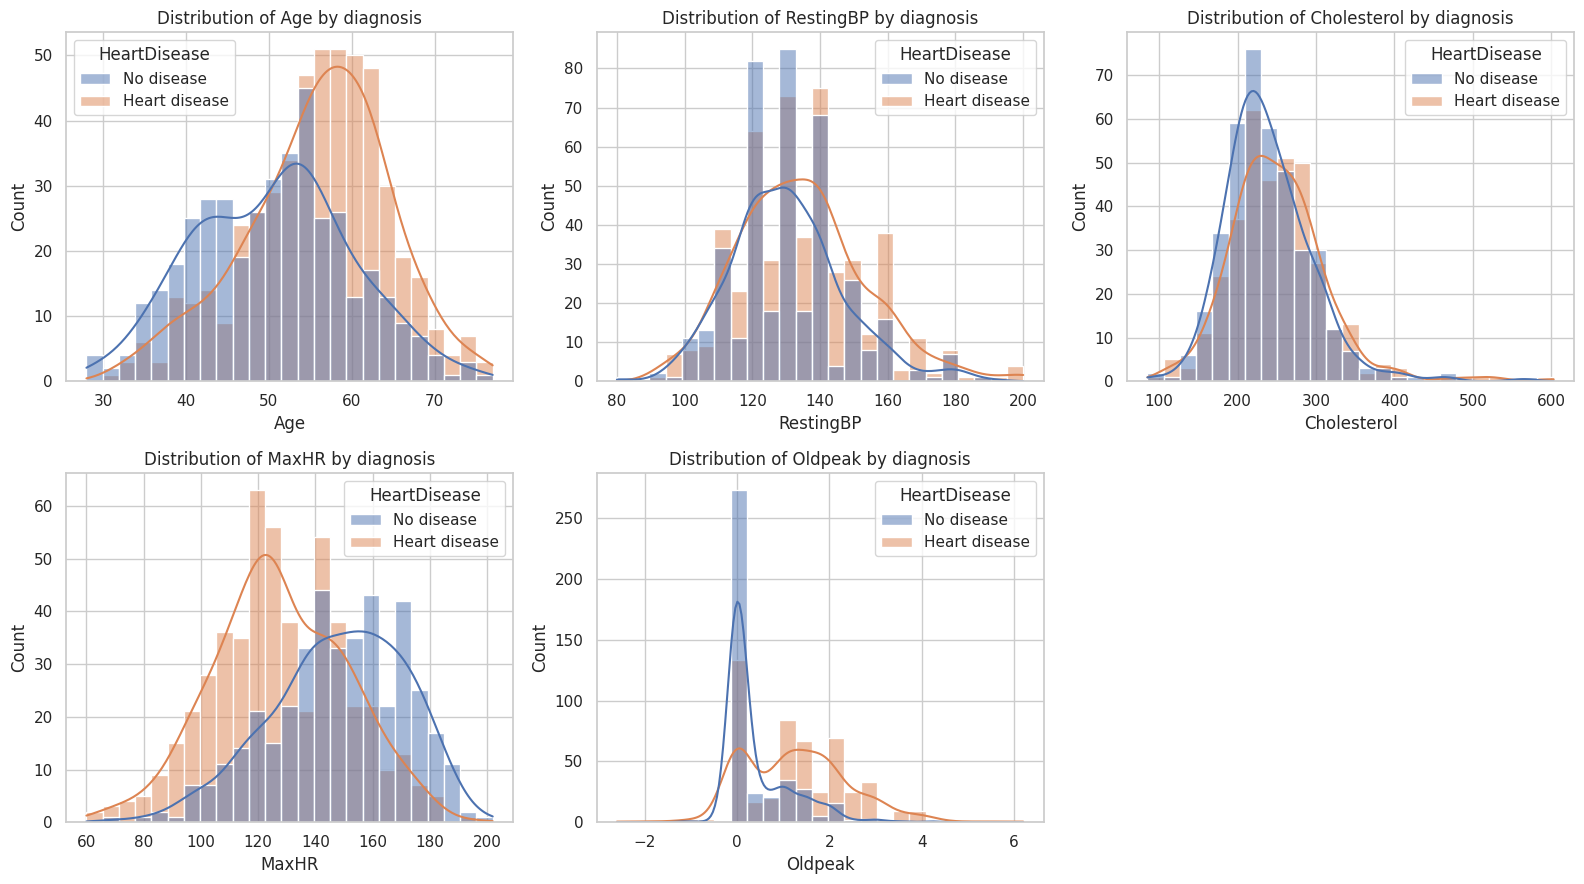

,Skewness,Kurtosis,Shapiro-Wilk p-value,Looks normal (p>0.05)?
Age,-0.196,-0.386,0.0000,No
RestingBP,0.607,0.792,0.0000,No
Cholesterol,1.239,4.529,0.0000,No
MaxHR,-0.144,-0.448,0.0002,No
Oldpeak,1.023,1.203,0.0000,No


Interpretation (distributions): the most skewed numeric variable is 'Cholesterol' (skewness = 1.24). A
skewness near 0 means a symmetric distribution; a positive value means a long right tail. The Shapiro-Wilk
test rejects normality for 5 of 5 numeric features (p < 0.05), which is common with several hundred
observations. None of the models used here requires normally distributed inputs, but distance-based models
(KNN) and logistic regression benefit from scaling, which is done inside the pipeline. The histograms coloured
by diagnosis show which features separate the two groups.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC):
    sns.histplot(x=data[col], hue=label, bins=25, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col} by diagnosis")
axes[-1].axis("off")
save_fig("02_numeric_distributions")

dist_table = pd.DataFrame({
    "Skewness": data[NUMERIC].skew().round(3),
    "Kurtosis": data[NUMERIC].kurt().round(3),
    "Shapiro-Wilk p-value": [round(stats.shapiro(data[c].dropna())[1], 4) for c in NUMERIC],
})
dist_table["Looks normal (p>0.05)?"] = np.where(dist_table["Shapiro-Wilk p-value"] > 0.05, "Yes", "No")
display(dist_table)

most_skewed = dist_table["Skewness"].abs().idxmax()
n_nonnormal = int((dist_table["Shapiro-Wilk p-value"] <= 0.05).sum())
say("dist",
    f"Interpretation (distributions): the most skewed numeric variable is '{most_skewed}' (skewness = {dist_table.loc[most_skewed, 'Skewness']:.2f}). "
    f"A skewness near 0 means a symmetric distribution; a positive value means a long right tail. The Shapiro-Wilk test rejects normality for "
    f"{n_nonnormal} of {len(NUMERIC)} numeric features (p < 0.05), which is common with several hundred observations. None of the models used here requires "
    f"normally distributed inputs, but distance-based models (KNN) and logistic regression benefit from scaling, which is done inside the pipeline. "
    f"The histograms coloured by diagnosis show which features separate the two groups.")

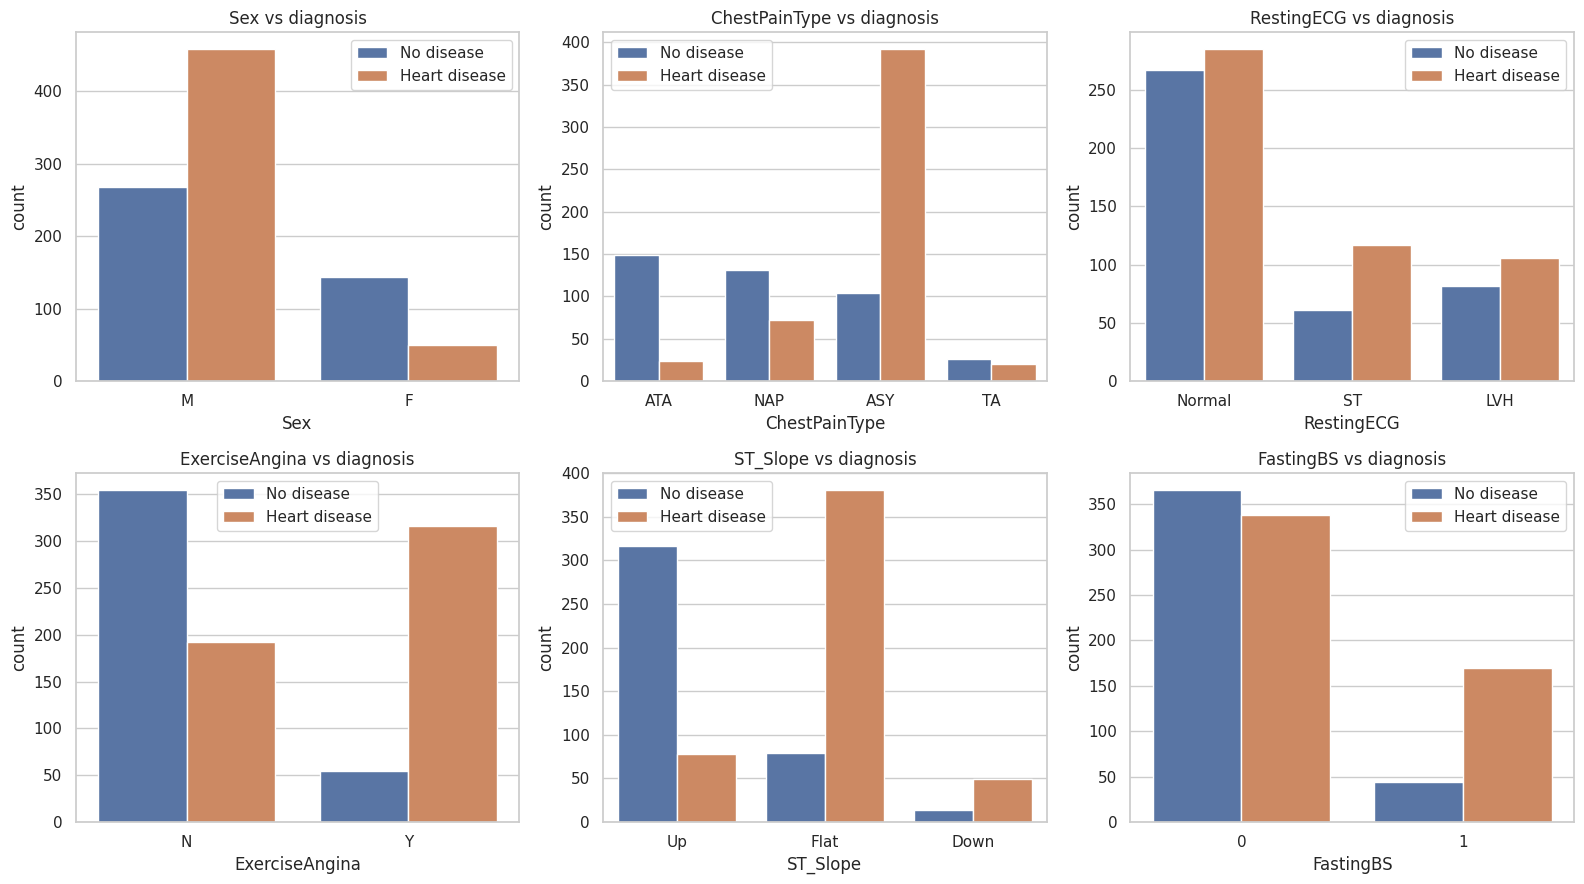

,Feature,Level,Patients,Disease rate (%)
0,Sex,F,193,25.9
1,Sex,M,725,63.2
2,ChestPainType,ASY,496,79.0
3,ChestPainType,ATA,173,13.9
4,ChestPainType,NAP,203,35.5
5,ChestPainType,TA,46,43.5
6,RestingECG,LVH,188,56.4
7,RestingECG,Normal,552,51.6
8,RestingECG,ST,178,65.7
9,ExerciseAngina,N,547,35.1


Interpretation (categorical features): the group with the highest disease rate is ExerciseAngina = Y (85.2% of
371 patients), while the lowest is ChestPainType = ATA (13.9% of 173 patients). Large gaps between the levels
of a feature show that the feature carries useful information for the classifier. (Only groups with at least
20 patients are compared.)


In [ ]:
# ---------------------------------------------------------------
# Categorical / binary features versus the target
# ---------------------------------------------------------------
cat_plot_cols = CATEGORICAL + BINARY
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_plot_cols):
    sns.countplot(data=data, x=col, hue=label, ax=ax)
    ax.set_title(f"{col} vs diagnosis")
    ax.legend(title="")
save_fig("03_categorical_vs_target")

rate_rows = []
for col in cat_plot_cols:
    g = data.groupby(col)[TARGET].agg(["count", "mean"])
    for lvl, r in g.iterrows():
        rate_rows.append({"Feature": col, "Level": str(lvl), "Patients": int(r["count"]), "Disease rate (%)": round(100 * r["mean"], 1)})
rate_table = pd.DataFrame(rate_rows)
display(rate_table)

pool = rate_table[rate_table["Patients"] >= 20]
hi = pool.sort_values("Disease rate (%)", ascending=False).iloc[0]
lo = pool.sort_values("Disease rate (%)", ascending=True).iloc[0]
say("categorical",
    f"Interpretation (categorical features): the group with the highest disease rate is {hi['Feature']} = {hi['Level']} "
    f"({hi['Disease rate (%)']:.1f}% of {int(hi['Patients'])} patients), while the lowest is {lo['Feature']} = {lo['Level']} "
    f"({lo['Disease rate (%)']:.1f}% of {int(lo['Patients'])} patients). Large gaps between the levels of a feature show that the feature carries "
    f"useful information for the classifier. (Only groups with at least 20 patients are compared.)")

## 1.5 Outlier detection

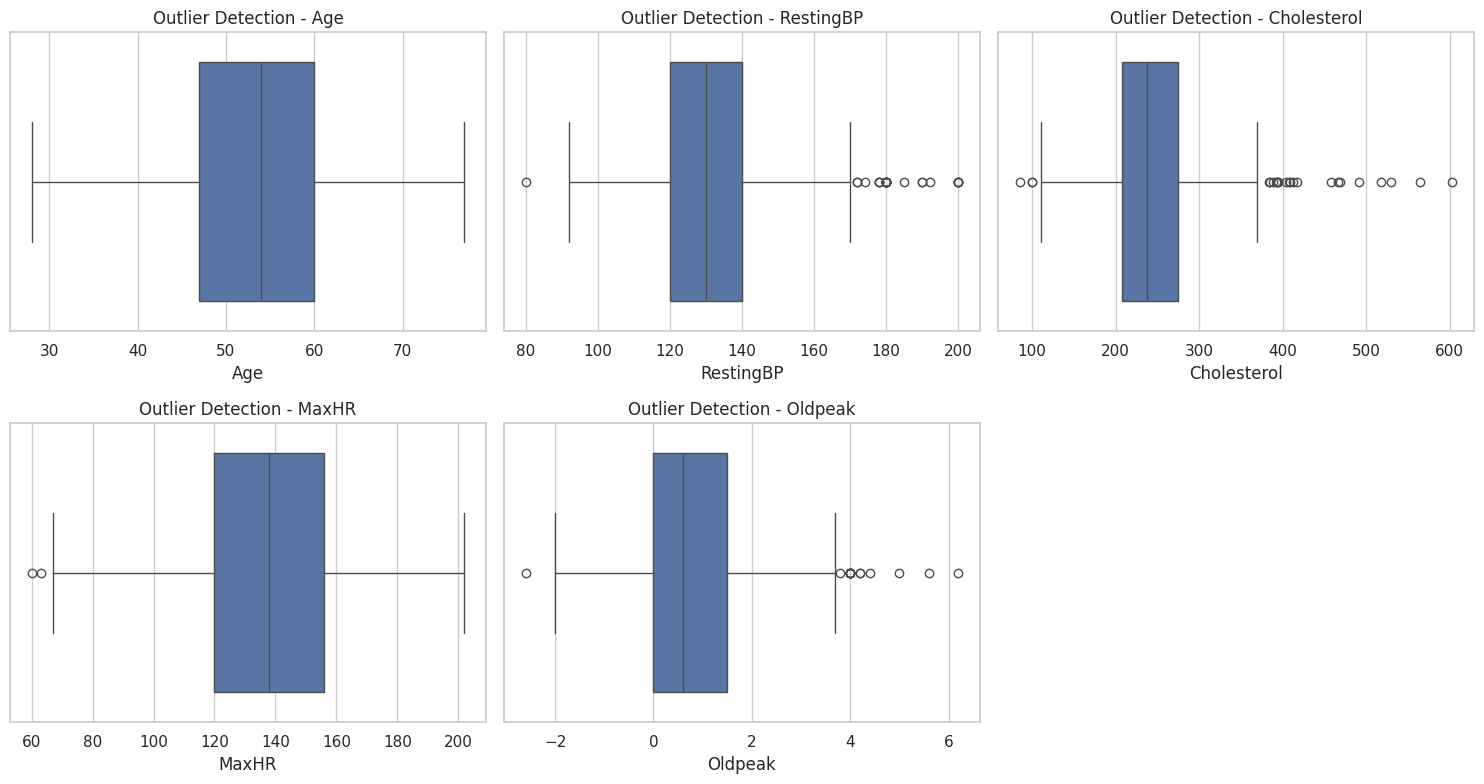

,Variable,Q1,Q3,Lower fence,Upper fence,Outliers (IQR rule),Outlier % (IQR),Outliers (|Z| > 3)
0,Age,47.00,60.0,27.50,79.50,0,0.00,0
1,RestingBP,120.00,140.0,90.00,170.00,27,2.94,7
2,Cholesterol,207.25,275.0,105.62,376.62,23,3.08,8
3,MaxHR,120.00,156.0,66.00,210.00,2,0.22,1
4,Oldpeak,0.00,1.5,-2.25,3.75,16,1.74,7


Interpretation (outliers) and decision: the IQR rule flags 68 outlying value(s) in total (variables affected:
RestingBP, Cholesterol, MaxHR, Oldpeak). The impossible zeros in Cholesterol and RestingBP were already
treated as missing values, so they are not counted as outliers here. The remaining extreme values are
physiologically possible readings from real patients (for example very high cholesterol or a high ST
depression), and removing them would discard exactly the sickest patients the model must recognise, so the
outliers are KEPT. Tree-based models are insensitive to them; for Logistic Regression and KNN, StandardScaler
is applied inside a pipeline.


In [ ]:
plt.figure(figsize=(15, 8))
for i, col in enumerate(NUMERIC):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x=data[col])
    plt.title(f"Outlier Detection - {col}")
save_fig("04_boxplots")

outlier_rows = []
for col in NUMERIC:
    s = data[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < low) | (s > high)).sum())
    n_z = int((np.abs(stats.zscore(s)) > 3).sum())
    outlier_rows.append({
        "Variable": col, "Q1": round(q1, 2), "Q3": round(q3, 2),
        "Lower fence": round(low, 2), "Upper fence": round(high, 2),
        "Outliers (IQR rule)": n_iqr, "Outlier % (IQR)": round(100 * n_iqr / len(s), 2),
        "Outliers (|Z| > 3)": n_z,
    })
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

n_out_total = int(outlier_table["Outliers (IQR rule)"].sum())
which = ", ".join(outlier_table.loc[outlier_table["Outliers (IQR rule)"] > 0, "Variable"]) or "none"
say("outliers",
    f"Interpretation (outliers) and decision: the IQR rule flags {n_out_total} outlying value(s) in total (variables affected: {which}). "
    f"The impossible zeros in Cholesterol and RestingBP were already treated as missing values, so they are not counted as outliers here. "
    f"The remaining extreme values are physiologically possible readings from real patients (for example very high cholesterol or a high ST depression), "
    f"and removing them would discard exactly the sickest patients the model must recognise, so the outliers are KEPT. "
    f"Tree-based models are insensitive to them; for Logistic Regression and KNN, StandardScaler is applied inside a pipeline.")

## 1.6 Correlation analysis

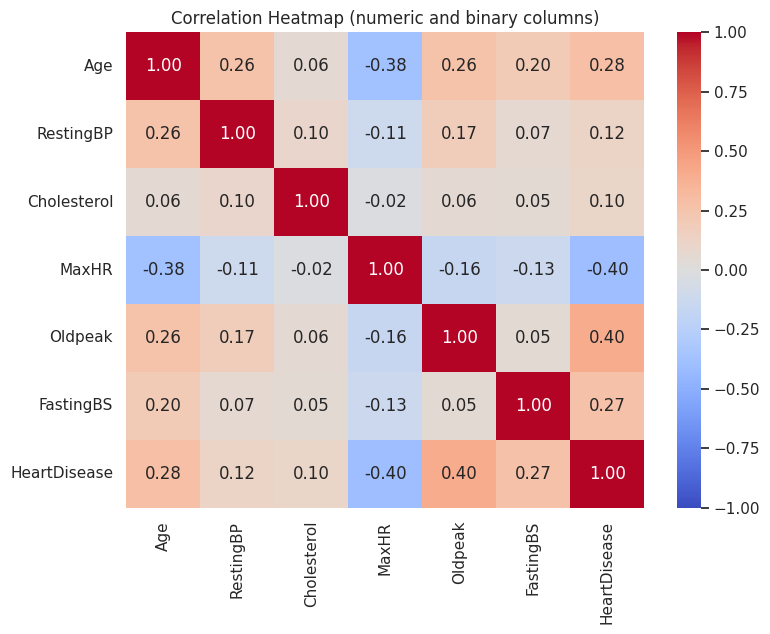

Correlation of every numeric / binary feature with HeartDisease:
Oldpeak        0.404
MaxHR         -0.400
Age            0.282
FastingBS      0.267
RestingBP      0.118
Cholesterol    0.104


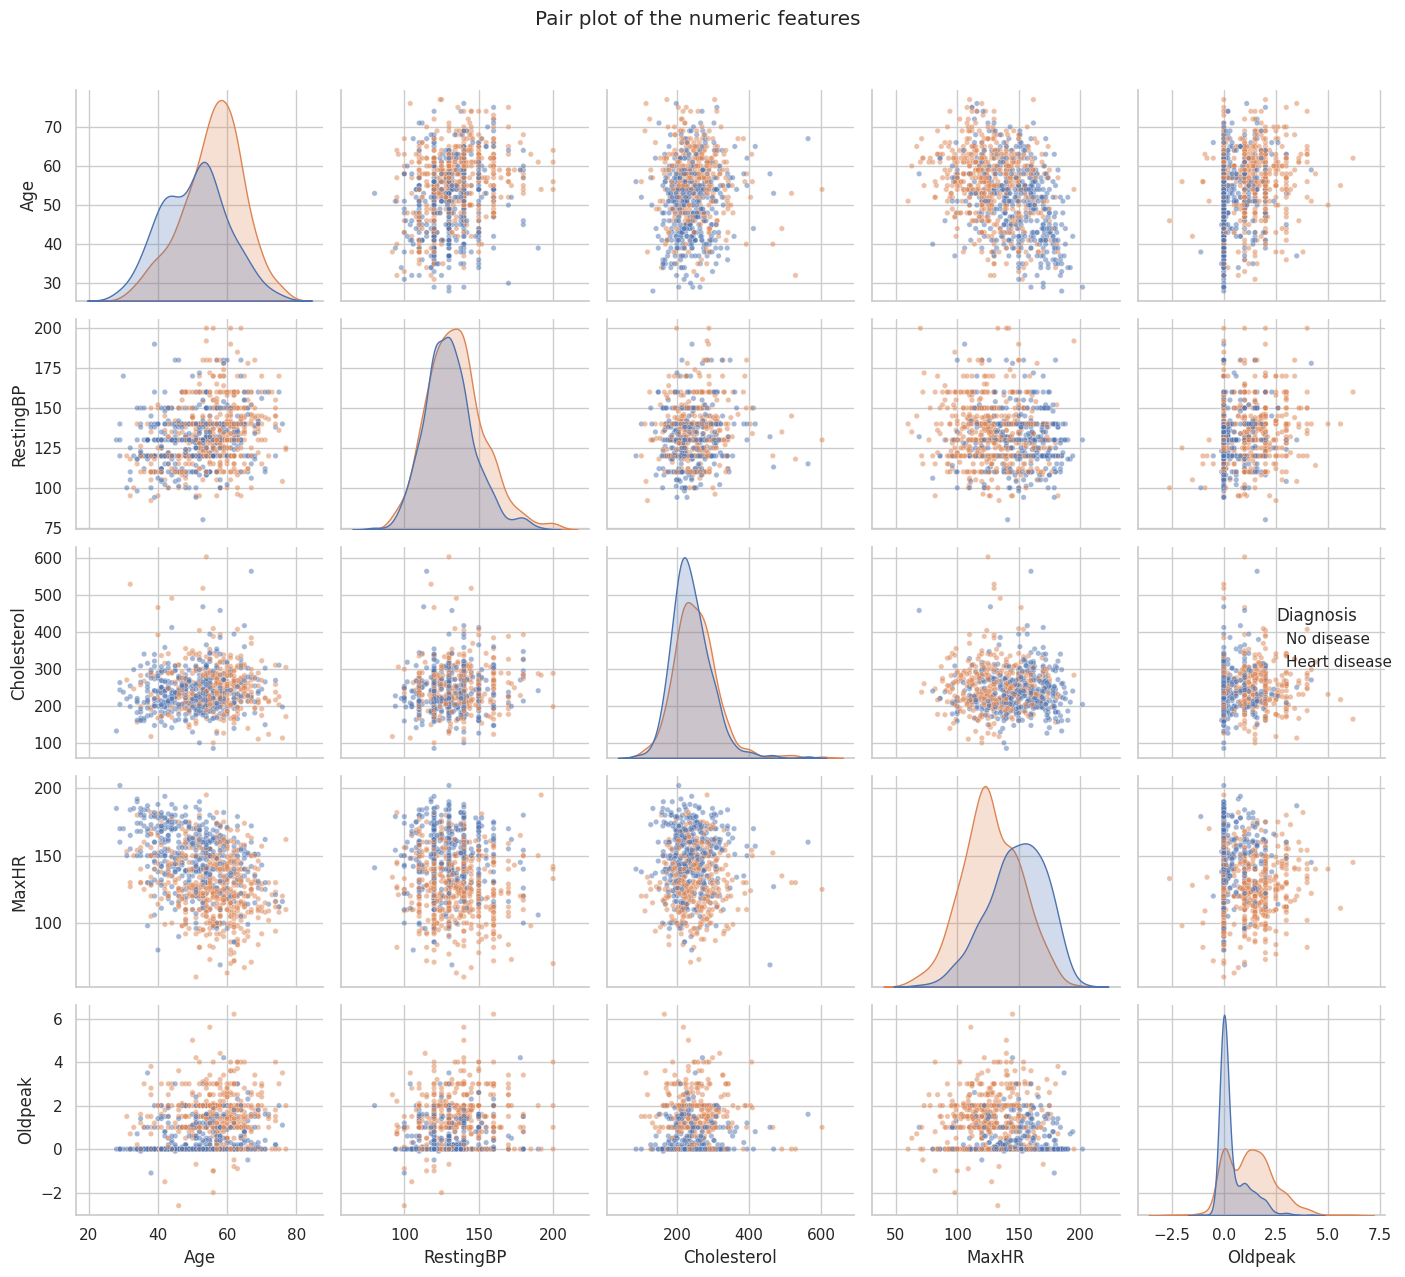

In [ ]:
corr_df = data[NUMERIC + BINARY + [TARGET]].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (numeric and binary columns)")
save_fig("05_correlation_heatmap")

corr_target = corr_df[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Correlation of every numeric / binary feature with HeartDisease:")
print(corr_target.round(3).to_string())

sns.pairplot(data[NUMERIC].assign(Diagnosis=label), hue="Diagnosis", diag_kind="kde", plot_kws={"alpha": 0.5, "s": 15})
plt.suptitle("Pair plot of the numeric features", y=1.02)
save_fig("06_pairplot")

In [ ]:
# Multicollinearity check between the numeric features (Variance Inflation Factor)
def vif_table(df):
    rows = []
    for col in df.columns:
        others = df.drop(columns=col)
        r2 = LinearRegression().fit(others, df[col]).score(others, df[col])
        rows.append({"Feature": col, "VIF": 1 / (1 - r2) if r2 < 1 else np.inf})
    return pd.DataFrame(rows)

num_filled = data[NUMERIC].fillna(data[NUMERIC].median())
vif = vif_table(num_filled)
display(vif.round(3))

top3 = ", ".join(f"{k} (r = {v:+.2f})" for k, v in corr_target.head(3).items())
say("corr",
    f"Interpretation (correlation): the numeric/binary features most strongly correlated with HeartDisease are {top3}. "
    f"For a 0/1 target this is a point-biserial correlation; a positive sign means that higher values go with a higher chance of disease and a negative sign "
    f"the opposite. Correlation only captures linear, one-feature-at-a-time relationships, so the categorical features (see the disease-rate table above) "
    f"and non-linear effects are handled by the models.")
say("vif",
    f"Multicollinearity: the VIF values are {', '.join(f'{r.Feature} = {r.VIF:.2f}' for r in vif.itertuples())}. A VIF below 5 means that the numeric features "
    f"are not strongly collinear with each other, so the Logistic Regression coefficients can be interpreted safely.")

,Feature,VIF
0,Age,1.288
1,RestingBP,1.094
2,Cholesterol,1.010
3,MaxHR,1.177
4,Oldpeak,1.092


Interpretation (correlation): the numeric/binary features most strongly correlated with HeartDisease are
Oldpeak (r = +0.40), MaxHR (r = -0.40), Age (r = +0.28). For a 0/1 target this is a point-biserial
correlation; a positive sign means that higher values go with a higher chance of disease and a negative sign
the opposite. Correlation only captures linear, one-feature-at-a-time relationships, so the categorical
features (see the disease-rate table above) and non-linear effects are handled by the models.
Multicollinearity: the VIF values are Age = 1.29, RestingBP = 1.09, Cholesterol = 1.01, MaxHR = 1.18, Oldpeak
= 1.09. A VIF below 5 means that the numeric features are not strongly collinear with each other, so the
Logistic Regression coefficients can be interpreted safely.


## 1.7 Feature encoding and preprocessing
The categorical columns are text, so they are **one-hot encoded**; numeric columns are **median-imputed** (this only affects the cholesterol / blood-pressure zeros) and **standardised** for the scale-sensitive models. Everything is wrapped in a `ColumnTransformer` **inside a `Pipeline`**, so imputer, scaler and encoder are fitted on the training data only (no data leakage). Tree-based models do not need scaling, so they use the same preprocessing without the scaler.

| Original | Transformation | Reason |
|---|---|---|
| `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak` | median imputation (+ `StandardScaler` for Logistic Regression and KNN) | fills the impossible zeros; KNN uses distances |
| `FastingBS` | passed through (already 0/1) | nothing to encode |
| `Sex`, `ExerciseAngina` | one-hot (one 0/1 column) | binary text categories |
| `ChestPainType`, `RestingECG`, `ST_Slope` | one-hot (one column per level) | nominal categories with no natural numeric order |

In [ ]:
def make_preprocessor(scale=True):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(num_steps), NUMERIC),
            ("bin", "passthrough", BINARY),
            ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CATEGORICAL),
        ],
        sparse_threshold=0,
    )

X = data[FEATURES].copy()
y = data[TARGET].astype(int).copy()

print("FEATURES:", FEATURES)
print("Input shape :", X.shape)
print("Target shape:", y.shape)
print("Missing values in features (NaN, to be imputed in the pipeline):", int(X.isnull().sum().sum()))
print("Missing values in target:", int(y.isnull().sum()))

demo_pre = make_preprocessor(True).fit(X)
encoded_names = [n.split("__", 1)[1] for n in demo_pre.get_feature_names_out()]
n_encoded = len(encoded_names)
print(f"\nAfter encoding the model sees {n_encoded} numeric columns:")
print(encoded_names)

FEATURES: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'FastingBS', 'Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Input shape : (918, 11)
Target shape: (918,)
Missing values in features (NaN, to be imputed in the pipeline): 173
Missing values in target: 0

After encoding the model sees 18 numeric columns:
['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'FastingBS', 'Sex_M', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']


## 1.8 Train-test split (70 : 30, stratified)
The rows are independent patients (not a time series), so a **random** 70 : 30 split is appropriate. `stratify=y` keeps the same disease / no-disease ratio in both parts, and `random_state` is fixed so the split is reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)

print("Training samples:", X_train.shape)
print("Testing samples :", X_test.shape)
print("Training percentage:", round(len(X_train) / len(data) * 100, 2))
print("Testing percentage :", round(len(X_test) / len(data) * 100, 2))

split_check = pd.DataFrame({
    "Set": ["Train", "Test"],
    "Patients": [len(y_train), len(y_test)],
    "Heart disease (count)": [int(y_train.sum()), int(y_test.sum())],
    "Heart disease (%)": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
})
display(split_check)

Training samples: (642, 11)
Testing samples : (276, 11)
Training percentage: 69.93
Testing percentage : 30.07


,Set,Patients,Heart disease (count),Heart disease (%)
0,Train,642,355,55.30
1,Test,276,153,55.43


---
# WEEK 1 — Baseline Modeling (Classification)

Required baselines: **Logistic Regression, Decision Tree, KNN**.
Metrics: **Accuracy, Precision, Recall, F1, ROC-AUC and the confusion matrix**. *All baselines are evaluated on exactly the same test set.*

> Regression models and metrics (MAE, RMSE, R²) are **not applicable** because `HeartDisease` is a class label.

In [ ]:
results = {}       # model name -> test metrics
predictions = {}   # model name -> predicted class
probas = {}        # model name -> predicted probability of heart disease
cms = {}           # model name -> confusion matrix
models = {}        # model name -> fitted pipeline

def evaluate_model(name, model, verbose=True):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_test, proba),
    }
    predictions[name], probas[name] = pred, proba
    cms[name] = confusion_matrix(y_test, pred)
    if verbose:
        print(name)
        for k, v in results[name].items():
            if k != "Model":
                print(f"  {k:<10}: {v:.4f}")
        print("-" * 40)

def results_table(names=None, sort_by="ROC-AUC"):
    table = pd.DataFrame(list(results.values()))
    if names is not None:
        table = table[table["Model"].isin(names)]
    return table.sort_values(sort_by, ascending=False).reset_index(drop=True)

# 1) Logistic Regression (scaling inside the pipeline)
lr_model = Pipeline([("pre", make_preprocessor(True)), ("model", LogisticRegression(max_iter=2000, random_state=SEED))])
lr_model.fit(X_train, y_train)
models["Logistic Regression"] = lr_model
evaluate_model("Logistic Regression", lr_model)

# 2) Decision Tree (no scaling needed)
dt_model = Pipeline([("pre", make_preprocessor(False)),
                     ("model", DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=SEED))])
dt_model.fit(X_train, y_train)
models["Decision Tree"] = dt_model
evaluate_model("Decision Tree", dt_model)

# 3) KNN (scaling is essential for distance-based models)
knn_model = Pipeline([("pre", make_preprocessor(True)), ("model", KNeighborsClassifier(n_neighbors=5))])
knn_model.fit(X_train, y_train)
models["KNN"] = knn_model
evaluate_model("KNN", knn_model)

Logistic Regression
  Accuracy  : 0.8768
  Precision : 0.8889
  Recall    : 0.8889
  F1        : 0.8889
  ROC-AUC   : 0.9305
----------------------------------------
Decision Tree
  Accuracy  : 0.8370
  Precision : 0.8418
  Recall    : 0.8693
  F1        : 0.8553
  ROC-AUC   : 0.8603
----------------------------------------
KNN
  Accuracy  : 0.8478
  Precision : 0.8581
  Recall    : 0.8693
  F1        : 0.8636
  ROC-AUC   : 0.9202
----------------------------------------


BASELINE MODEL COMPARISON TABLE (same test set: 276 patients)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8768,0.8889,0.8889,0.8889,0.9305
1,KNN,0.8478,0.8581,0.8693,0.8636,0.9202
2,Decision Tree,0.8370,0.8418,0.8693,0.8553,0.8603


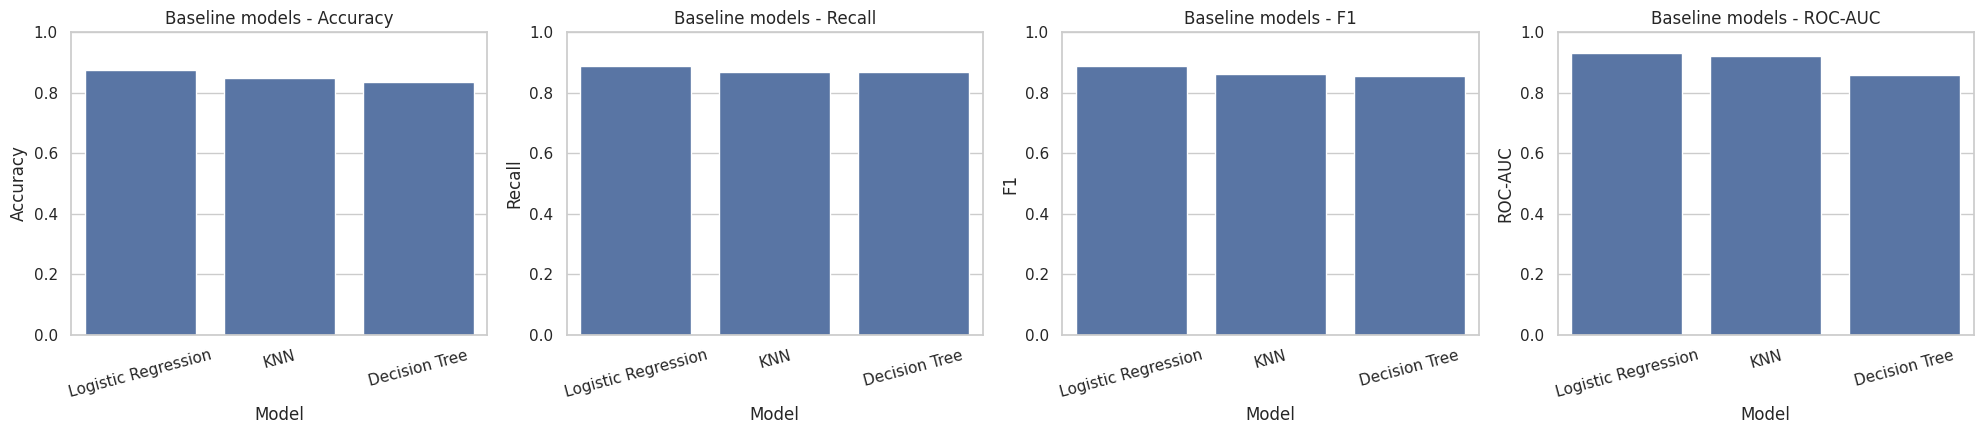

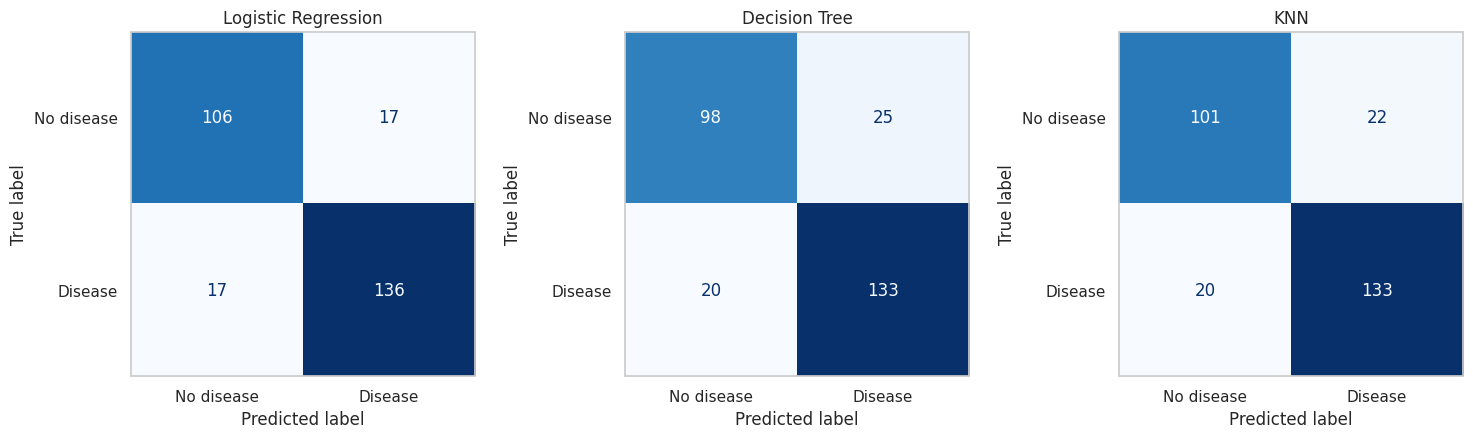

Interpretation (baselines): among the baseline models, Logistic Regression performed best with ROC-AUC =
0.930, accuracy = 0.877, recall = 0.889, precision = 0.889 and F1 = 0.889, while Decision Tree was the weakest
(ROC-AUC = 0.860, F1 = 0.855). The linear Logistic Regression (ROC-AUC 0.930) was at least as good as the
single Decision Tree (ROC-AUC 0.860), which shows that a simple linear model already captures most of the
signal and that a single tree tends to over-fit a small dataset. KNN depends on distances between scaled
features, so it is sensitive to the choice of k and to uninformative features. Recall is the share of sick
patients that are found; precision is the share of predicted-sick patients that are really sick; ROC-AUC
measures how well the model ranks sick patients above healthy ones at every threshold. These baselines set the
reference performance that the advanced models of Week 2 must beat.


In [ ]:
BASELINE_MODELS = ["Logistic Regression", "Decision Tree", "KNN"]
baseline_results = results_table(BASELINE_MODELS)
print(f"BASELINE MODEL COMPARISON TABLE (same test set: {len(y_test)} patients)")
display(baseline_results.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, metric in zip(axes, ["Accuracy", "Recall", "F1", "ROC-AUC"]):
    sns.barplot(data=baseline_results, x="Model", y=metric, ax=ax)
    ax.set_title(f"Baseline models - {metric}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
save_fig("07_baseline_comparison")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, BASELINE_MODELS):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], ax=ax, colorbar=False,
                                            display_labels=["No disease", "Disease"], cmap="Blues")
    ax.set_title(name)
    ax.grid(False)
save_fig("08_baseline_confusion")

best_b, worst_b = baseline_results.iloc[0], baseline_results.iloc[-1]
lr_r, dt_r = results["Logistic Regression"], results["Decision Tree"]
if dt_r["ROC-AUC"] > lr_r["ROC-AUC"] + 0.005:
    nonlin = (f"The non-linear Decision Tree (ROC-AUC {dt_r['ROC-AUC']:.3f}) beat the linear Logistic Regression (ROC-AUC {lr_r['ROC-AUC']:.3f}), "
              f"which suggests that the relationship between the clinical measurements and heart disease is not purely linear.")
else:
    nonlin = (f"The linear Logistic Regression (ROC-AUC {lr_r['ROC-AUC']:.3f}) was at least as good as the single Decision Tree (ROC-AUC {dt_r['ROC-AUC']:.3f}), "
              f"which shows that a simple linear model already captures most of the signal and that a single tree tends to over-fit a small dataset.")
say("baseline",
    f"Interpretation (baselines): among the baseline models, {best_b['Model']} performed best with ROC-AUC = {best_b['ROC-AUC']:.3f}, accuracy = {best_b['Accuracy']:.3f}, "
    f"recall = {best_b['Recall']:.3f}, precision = {best_b['Precision']:.3f} and F1 = {best_b['F1']:.3f}, while {worst_b['Model']} was the weakest "
    f"(ROC-AUC = {worst_b['ROC-AUC']:.3f}, F1 = {worst_b['F1']:.3f}). {nonlin} KNN depends on distances between scaled features, so it is sensitive to the choice of k and to "
    f"uninformative features. Recall is the share of sick patients that are found; precision is the share of predicted-sick patients that are really sick; "
    f"ROC-AUC measures how well the model ranks sick patients above healthy ones at every threshold. These baselines set the reference performance that the advanced "
    f"models of Week 2 must beat.")

---
# WEEK 2 — Advanced Modeling & Optimization

* **Random Forest** and **Gradient Boosting / XGBoost**
* **Hyper-parameter tuning:** `GridSearchCV` for every advanced model (scored by ROC-AUC)
* **Cross-validation:** 5-fold *stratified* CV on the training data (the test set is never used for tuning or selection)
* **Classification-specific analysis:** ROC curves, confusion matrix, threshold analysis and feature importance

(Residual analysis, MAE, RMSE and R² are regression-only tools and are not applicable here.)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuning_summary = []

def run_grid(tuned_name, pipe, grid):
    g = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    g.fit(X_train, y_train)
    n_cand = len(g.cv_results_["params"])
    models[tuned_name] = g.best_estimator_
    best_params = {k.replace("model__", ""): v for k, v in g.best_params_.items()}
    tuning_summary.append({
        "Model": tuned_name, "Method": "GridSearchCV", "Candidates": n_cand, "Fits": n_cand * cv.get_n_splits(),
        "Best parameters": str(best_params), "CV ROC-AUC": g.best_score_,
    })
    print(f"{tuned_name}: best CV ROC-AUC = {g.best_score_:.4f}   ({n_cand} candidates, {n_cand * 5} fits)")
    print("   best parameters:", best_params)
    evaluate_model(tuned_name, g.best_estimator_, verbose=False)

specs = [
    ("Tuned Logistic Regression",
     Pipeline([("pre", make_preprocessor(True)), ("model", LogisticRegression(max_iter=3000, random_state=SEED))]),
     {"model__C": [0.01, 0.1, 1, 10, 100]}),
    ("Tuned Decision Tree",
     Pipeline([("pre", make_preprocessor(False)), ("model", DecisionTreeClassifier(random_state=SEED))]),
     {"model__max_depth": [2, 3, 4, 5, 6, 8], "model__min_samples_split": [2, 5, 10, 20], "model__min_samples_leaf": [1, 2, 5, 10]}),
    ("Tuned KNN",
     Pipeline([("pre", make_preprocessor(True)), ("model", KNeighborsClassifier())]),
     {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
    ("Tuned Random Forest",
     Pipeline([("pre", make_preprocessor(False)), ("model", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
     {"model__n_estimators": [100, 200, 300], "model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 2, 4]}),
    ("Tuned Gradient Boosting",
     Pipeline([("pre", make_preprocessor(False)), ("model", GradientBoostingClassifier(random_state=SEED))]),
     {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3], "model__subsample": [0.8, 1.0]}),
]
if HAS_XGB:
    specs.append((
        "Tuned XGBoost",
        Pipeline([("pre", make_preprocessor(False)),
                  ("model", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, tree_method="hist"))]),
        {"model__n_estimators": [100, 200], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.05, 0.1],
         "model__subsample": [0.8, 1.0]},
    ))

for tuned_name, pipe, grid in specs:
    run_grid(tuned_name, pipe, grid)

print("\nHYPER-PARAMETER TUNING SUMMARY")
tuning_table = pd.DataFrame(tuning_summary).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
display(tuning_table)

best_cv_row = tuning_table.iloc[0]
say("tuning",
    f"Interpretation (tuning): GridSearchCV evaluates every combination of the parameter grid with 5-fold stratified cross-validation and keeps the one with the highest "
    f"ROC-AUC. The best tuned model is {best_cv_row['Model']} (CV ROC-AUC = {best_cv_row['CV ROC-AUC']:.3f}). The tuning is done on the training data only, so the test set "
    f"stays untouched for the final, unbiased evaluation. Limiting max_depth, the number of trees or the learning rate controls over-fitting, which is important with "
    f"a dataset of only {n_rows} patients.")

Tuned Logistic Regression: best CV ROC-AUC = 0.9142   (5 candidates, 25 fits)
   best parameters: {'C': 1}
Tuned Decision Tree: best CV ROC-AUC = 0.8996   (96 candidates, 480 fits)
   best parameters: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Tuned KNN: best CV ROC-AUC = 0.9098   (28 candidates, 140 fits)
   best parameters: {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
Tuned Random Forest: best CV ROC-AUC = 0.9200   (36 candidates, 180 fits)
   best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Tuned Gradient Boosting: best CV ROC-AUC = 0.9182   (24 candidates, 120 fits)
   best parameters: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}
Tuned XGBoost: best CV ROC-AUC = 0.9182   (36 candidates, 180 fits)
   best parameters: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}

HYPER-PARAMETER TUNING SUMMARY


,Model,Method,Candidates,Fits,Best parameters,CV ROC-AUC
0,Tuned Random Forest,GridSearchCV,36,180,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",0.920018
1,Tuned XGBoost,GridSearchCV,36,180,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.918244
2,Tuned Gradient Boosting,GridSearchCV,24,120,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.918152
3,Tuned Logistic Regression,GridSearchCV,5,25,{'C': 1},0.914194
4,Tuned KNN,GridSearchCV,28,140,"{'n_neighbors': 21, 'p': 1, 'weights': 'distan...",0.909847
5,Tuned Decision Tree,GridSearchCV,96,480,"{'max_depth': 3, 'min_samples_leaf': 2, 'min_s...",0.899553


Interpretation (tuning): GridSearchCV evaluates every combination of the parameter grid with 5-fold stratified
cross-validation and keeps the one with the highest ROC-AUC. The best tuned model is Tuned Random Forest (CV
ROC-AUC = 0.920). The tuning is done on the training data only, so the test set stays untouched for the final,
unbiased evaluation. Limiting max_depth, the number of trees or the learning rate controls over-fitting, which
is important with a dataset of only 918 patients.


### Cross-validation of all models
Every model (baselines and tuned models) is re-scored with the **same 5 stratified folds** on the training data, so the comparison is fair. (Tuned models were selected on the same folds, so their CV scores are slightly optimistic — the untouched test set gives the final, unbiased result.)

5-FOLD STRATIFIED CROSS-VALIDATION RESULTS (training data)


,Model,CV ROC-AUC (mean),CV ROC-AUC (std),CV Accuracy,CV Recall,CV F1
0,Tuned Random Forest,0.920018,0.024092,0.842769,0.887324,0.862332
1,Tuned XGBoost,0.918244,0.027472,0.859859,0.887324,0.875394
2,Tuned Gradient Boosting,0.918152,0.027704,0.848970,0.881690,0.866293
3,Logistic Regression,0.914194,0.032475,0.836470,0.856338,0.852588
4,Tuned Logistic Regression,0.914194,0.032475,0.836470,0.856338,0.852588
5,Tuned KNN,0.909847,0.026758,0.841146,0.878873,0.859727
6,Tuned Decision Tree,0.899553,0.024060,0.820942,0.836620,0.838022
7,KNN,0.874046,0.020353,0.830220,0.867606,0.849758
8,Decision Tree,0.862339,0.023644,0.800654,0.839437,0.823207


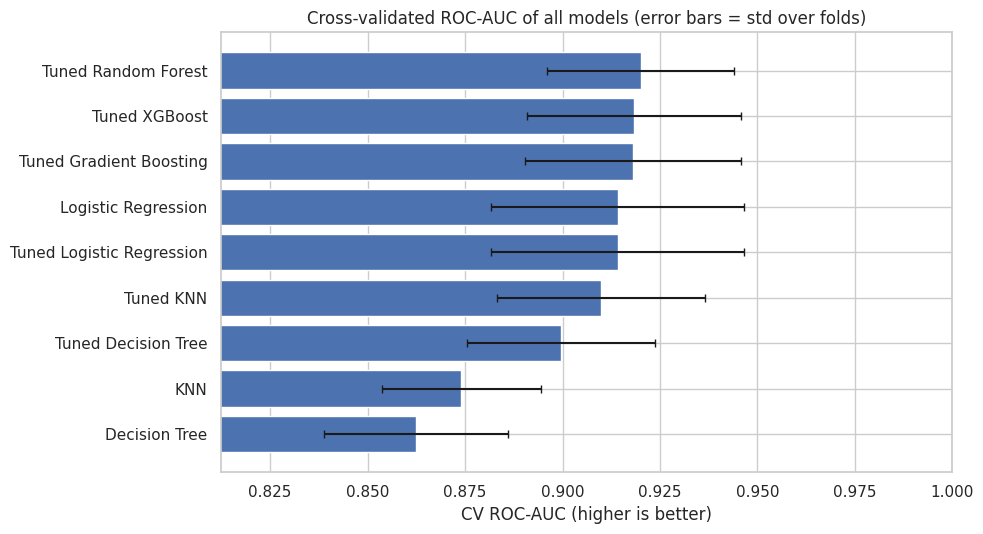

Interpretation (cross-validation): Tuned Random Forest has the highest average validation ROC-AUC (0.920 +/-
0.024), with CV accuracy 0.843, recall 0.887 and F1 0.862. The standard deviation shows how stable each model
is across the folds; when the difference between two models is smaller than this fold-to-fold variation, the
ranking should not be over-interpreted.


In [ ]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows, cv_auc = [], {}
for name, estimator in models.items():
    sc = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_auc[name] = sc["test_roc_auc"].mean()
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC (mean)": sc["test_roc_auc"].mean(),
        "CV ROC-AUC (std)": sc["test_roc_auc"].std(),
        "CV Accuracy": sc["test_accuracy"].mean(),
        "CV Recall": sc["test_recall"].mean(),
        "CV F1": sc["test_f1"].mean(),
    })
cv_table = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC (mean)", ascending=False).reset_index(drop=True)
print("5-FOLD STRATIFIED CROSS-VALIDATION RESULTS (training data)")
display(cv_table)

plt.figure(figsize=(10, 5.5))
plt.barh(cv_table["Model"][::-1], cv_table["CV ROC-AUC (mean)"][::-1], xerr=cv_table["CV ROC-AUC (std)"][::-1], capsize=3)
plt.xlabel("CV ROC-AUC (higher is better)")
plt.xlim(max(0.5, cv_table["CV ROC-AUC (mean)"].min() - 0.05), 1.0)
plt.title("Cross-validated ROC-AUC of all models (error bars = std over folds)")
save_fig("09_cv_auc")

top_cv = cv_table.iloc[0]
say("cv",
    f"Interpretation (cross-validation): {top_cv['Model']} has the highest average validation ROC-AUC ({top_cv['CV ROC-AUC (mean)']:.3f} +/- {top_cv['CV ROC-AUC (std)']:.3f}), "
    f"with CV accuracy {top_cv['CV Accuracy']:.3f}, recall {top_cv['CV Recall']:.3f} and F1 {top_cv['CV F1']:.3f}. The standard deviation shows how stable each model is across the folds; "
    f"when the difference between two models is smaller than this fold-to-fold variation, the ranking should not be over-interpreted.")

FINAL MODEL COMPARISON (sorted by test ROC-AUC; CV ROC-AUC = validation on the training data)


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
0,1,Tuned KNN,0.8949,0.9189,0.8889,0.9037,0.9443,0.9098
1,2,Tuned Random Forest,0.8804,0.8896,0.8954,0.8925,0.9366,0.9200
2,3,Tuned Gradient Boosting,0.8949,0.8924,0.9216,0.9068,0.9353,0.9182
3,4,Tuned XGBoost,0.8913,0.8917,0.9150,0.9032,0.9348,0.9182
4,5,Logistic Regression,0.8768,0.8889,0.8889,0.8889,0.9305,0.9142
5,6,Tuned Logistic Regression,0.8768,0.8889,0.8889,0.8889,0.9305,0.9142
6,7,KNN,0.8478,0.8581,0.8693,0.8636,0.9202,0.8740
7,8,Tuned Decision Tree,0.8551,0.8951,0.8366,0.8649,0.9147,0.8996
8,9,Decision Tree,0.8370,0.8418,0.8693,0.8553,0.8603,0.8623



SELECTED MODEL (highest cross-validated ROC-AUC): Tuned Random Forest
Note: the model with the highest TEST ROC-AUC is Tuned KNN - it is NOT used for selection, to keep the test set unbiased.


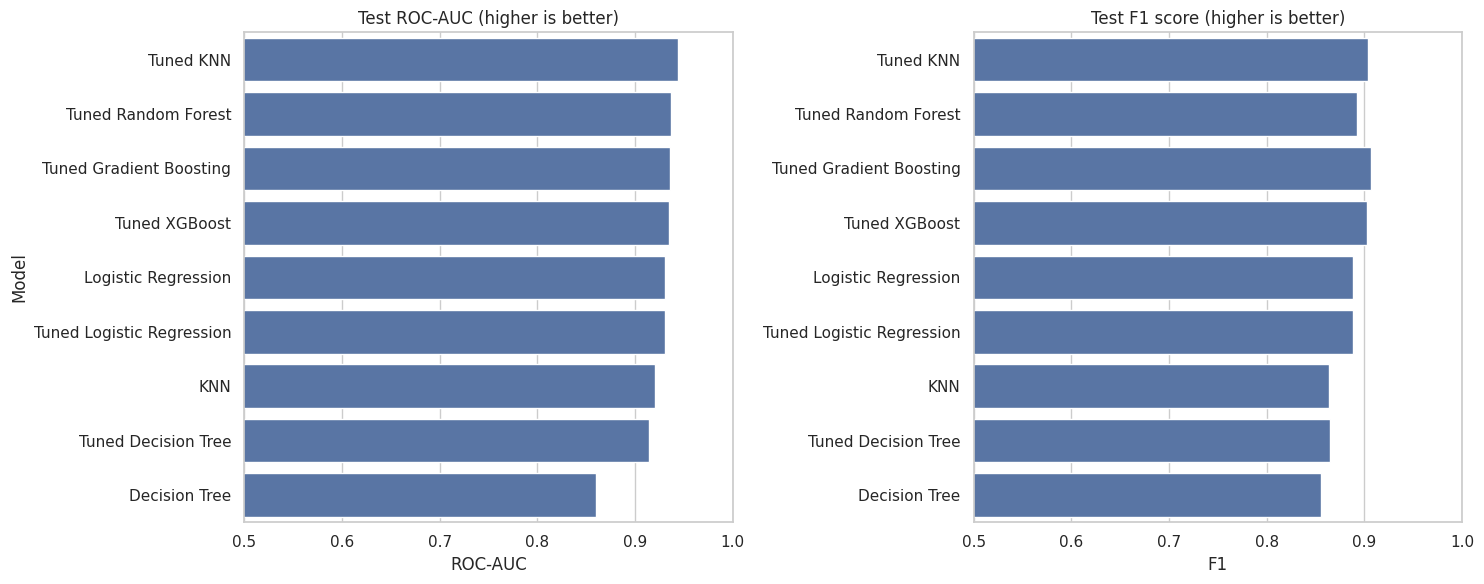

In [ ]:
# ---------------------------------------------------------------
# FINAL MODEL COMPARISON (all models, same test set)
# ---------------------------------------------------------------
final_comparison = results_table()
final_comparison["CV ROC-AUC"] = final_comparison["Model"].map(cv_auc)
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))
print("FINAL MODEL COMPARISON (sorted by test ROC-AUC; CV ROC-AUC = validation on the training data)")
display(final_comparison.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "CV ROC-AUC"]}))

# MODEL SELECTION uses ONLY the cross-validated ROC-AUC. The test set is used once, for the final evaluation.
cv_pool = final_comparison.sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
best_model_name = cv_pool.iloc[0]["Model"]
runner_up_name = cv_pool.iloc[1]["Model"]
best_model = models[best_model_name]
best_pred, best_proba = predictions[best_model_name], probas[best_model_name]
print("\nSELECTED MODEL (highest cross-validated ROC-AUC):", best_model_name)
if final_comparison.iloc[0]["Model"] != best_model_name:
    print("Note: the model with the highest TEST ROC-AUC is", final_comparison.iloc[0]["Model"],
          "- it is NOT used for selection, to keep the test set unbiased.")

order = final_comparison["Model"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=final_comparison, y="Model", x="ROC-AUC", order=order, ax=axes[0])
axes[0].set_title("Test ROC-AUC (higher is better)")
axes[0].set_xlim(0.5, 1.0)
sns.barplot(data=final_comparison, y="Model", x="F1", order=order, ax=axes[1])
axes[1].set_title("Test F1 score (higher is better)")
axes[1].set_ylabel("")
axes[1].set_xlim(0.5, 1.0)
save_fig("10_model_comparison")

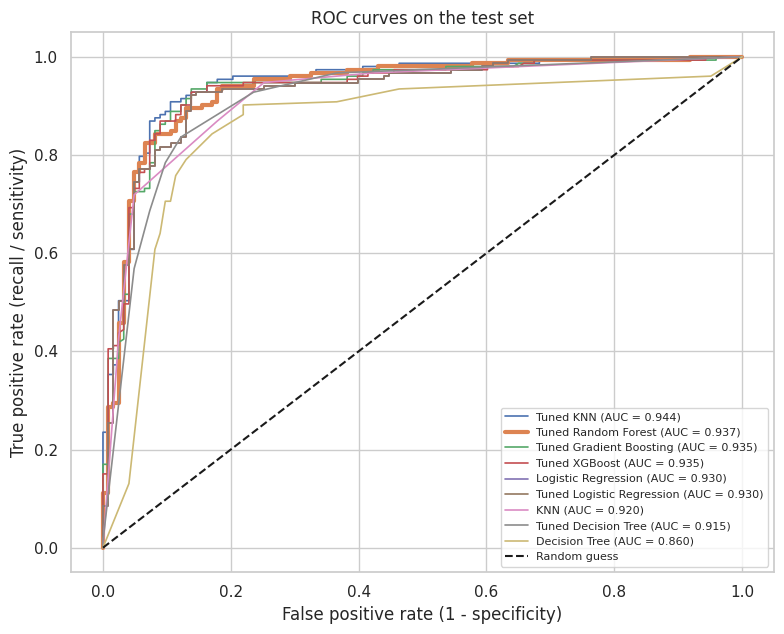

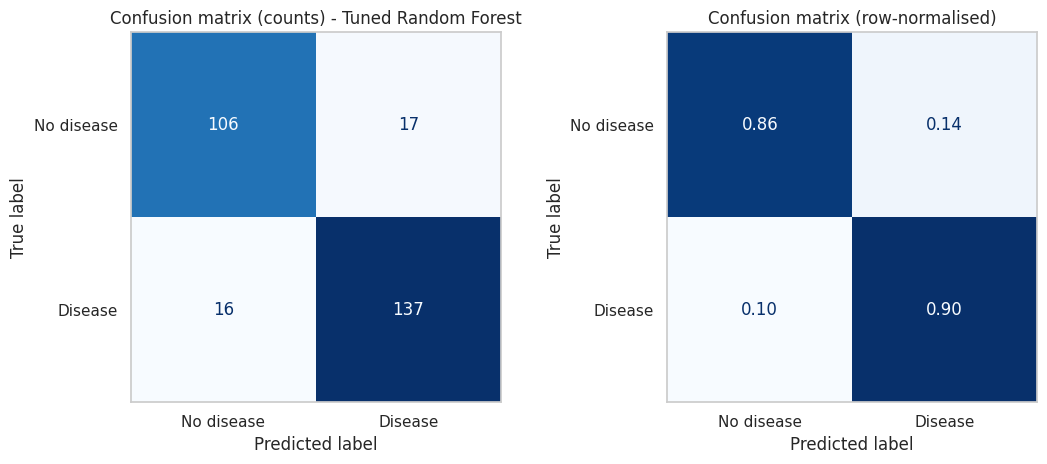

               precision    recall  f1-score   support

   No disease      0.869     0.862     0.865       123
Heart disease      0.890     0.895     0.893       153

     accuracy                          0.880       276
    macro avg      0.879     0.879     0.879       276
 weighted avg      0.880     0.880     0.880       276



In [ ]:
# ROC curves of all models + confusion matrices of the selected model
plt.figure(figsize=(8, 6.5))
for name in final_comparison["Model"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    lw = 3 if name == best_model_name else 1.2
    plt.plot(fpr, tpr, lw=lw, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (recall / sensitivity)")
plt.title("ROC curves on the test set")
plt.legend(fontsize=8, loc="lower right")
save_fig("11_roc_curves")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, ax=axes[0], colorbar=False,
                                        display_labels=["No disease", "Disease"], cmap="Blues")
axes[0].set_title(f"Confusion matrix (counts) - {best_model_name}")
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, ax=axes[1], colorbar=False, normalize="true",
                                        display_labels=["No disease", "Disease"], cmap="Blues", values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised)")
for a in axes:
    a.grid(False)
save_fig("12_confusion_selected")

print(classification_report(y_test, best_pred, target_names=["No disease", "Heart disease"], digits=3))
cr_df = pd.DataFrame(classification_report(y_test, best_pred, target_names=["No disease", "Heart disease"],
                                           output_dict=True)).T.round(3).reset_index().rename(columns={"index": "Class"})
cr_df["support"] = cr_df["support"].astype(int)

### Error analysis (replaces the residual analysis of a regression project)
For a classifier the "errors" are the **false negatives** (sick patient predicted healthy) and the **false positives** (healthy patient predicted sick). The default decision threshold is 0.5; lowering it finds more sick patients (higher recall) at the price of more false alarms.

In [ ]:
tn, fp, fn, tp = cms[best_model_name].ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
say("error",
    f"Error analysis of the selected model ({best_model_name}) on {len(y_test)} test patients: it correctly identified {tp} of {tp + fn} patients with heart disease "
    f"(sensitivity / recall = {sensitivity:.3f}) and {tn} of {tn + fp} healthy patients (specificity = {specificity:.3f}). It made {fn} false-negative error(s) "
    f"(sick patients predicted healthy - the most serious mistake in screening) and {fp} false-positive error(s) (healthy patients sent for extra tests). "
    f"The ROC curve shows that all tuned models rank patients far better than random guessing (the diagonal).")

# Threshold analysis for the selected model (illustration only - a real threshold would be chosen on validation data)
thr_rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (best_proba >= thr).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    thr_rows.append({"Threshold": thr, "Precision": precision_score(y_test, p, zero_division=0),
                     "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p),
                     "False negatives": int(fn_), "False positives": int(fp_)})
threshold_table = pd.DataFrame(thr_rows)
display(threshold_table.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "Threshold": "{:.1f}"}))
say("threshold",
    f"Threshold analysis: moving the decision threshold from 0.5 down to 0.3 changes the number of false negatives from "
    f"{int(threshold_table.loc[threshold_table['Threshold'] == 0.5, 'False negatives'].iloc[0])} to {int(threshold_table.loc[threshold_table['Threshold'] == 0.3, 'False negatives'].iloc[0])} "
    f"and the number of false positives from {int(threshold_table.loc[threshold_table['Threshold'] == 0.5, 'False positives'].iloc[0])} to "
    f"{int(threshold_table.loc[threshold_table['Threshold'] == 0.3, 'False positives'].iloc[0])}. In a screening setting a lower threshold may be preferred because missing a "
    f"sick patient is worse than an extra check-up. This table is computed on the test set for illustration; in practice the threshold should be chosen on validation data.")

Error analysis of the selected model (Tuned Random Forest) on 276 test patients: it correctly identified 137
of 153 patients with heart disease (sensitivity / recall = 0.895) and 106 of 123 healthy patients (specificity
= 0.862). It made 16 false-negative error(s) (sick patients predicted healthy - the most serious mistake in
screening) and 17 false-positive error(s) (healthy patients sent for extra tests). The ROC curve shows that
all tuned models rank patients far better than random guessing (the diagonal).


,Threshold,Precision,Recall,F1,False negatives,False positives
0,0.3,0.795,0.961,0.870,6,38
1,0.4,0.862,0.941,0.900,9,23
2,0.5,0.890,0.895,0.893,16,17
3,0.6,0.908,0.843,0.875,24,13
4,0.7,0.951,0.765,0.848,36,6


Threshold analysis: moving the decision threshold from 0.5 down to 0.3 changes the number of false negatives
from 16 to 6 and the number of false positives from 17 to 38. In a screening setting a lower threshold may be
preferred because missing a sick patient is worse than an extra check-up. This table is computed on the test
set for illustration; in practice the threshold should be chosen on validation data.


### Feature importance
Three complementary views: **permutation importance** of the selected model (drop in test ROC-AUC when one original feature is shuffled), **Random Forest impurity importance** and the **standardised Logistic Regression coefficients** (on the one-hot encoded columns).

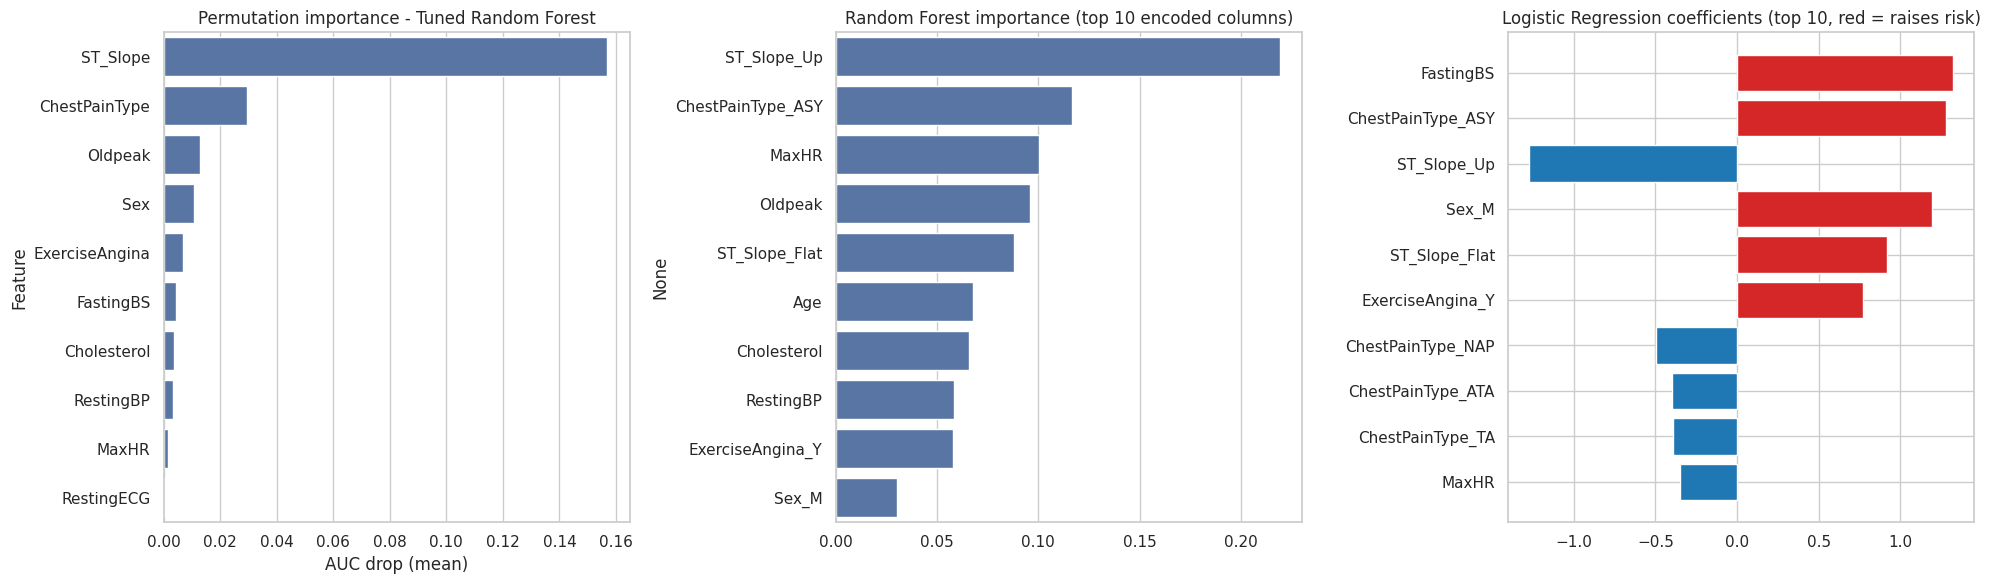

,Feature,AUC drop (mean),AUC drop (std)
0,ST_Slope,0.1569,0.0202
1,ChestPainType,0.0295,0.0106
2,Oldpeak,0.0130,0.0042
3,Sex,0.0108,0.0044
4,ExerciseAngina,0.0070,0.0040
5,FastingBS,0.0042,0.0027
6,Cholesterol,0.0038,0.0021
7,RestingBP,0.0033,0.0020
8,MaxHR,0.0016,0.0051
9,RestingECG,0.0005,0.0019


Interpretation (feature importance): shuffling ST_Slope reduces the test ROC-AUC of the selected model the
most (0.157), followed by ChestPainType (0.029) and Oldpeak (0.013). Features whose shuffling changes the AUC
by about zero or less (RestingECG, Age) add little beyond the others. The Random Forest's most important
encoded columns are ST_Slope_Up, ChestPainType_ASY, MaxHR, and the largest Logistic Regression coefficients
belong to FastingBS, ChestPainType_ASY, ST_Slope_Up. When several independent views agree, there is more
confidence that the model has learned real relationships rather than noise. These are associations in the
data, not proof of cause and effect.


In [ ]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=1)
perm_table = pd.DataFrame({"Feature": FEATURES, "AUC drop (mean)": perm.importances_mean, "AUC drop (std)": perm.importances_std})
perm_table = perm_table.sort_values("AUC drop (mean)", ascending=False).reset_index(drop=True)

rf_pipe = models["Tuned Random Forest"]
rf_names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["pre"].get_feature_names_out()]
rf_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=rf_names).sort_values(ascending=False)

lr_pipe = models["Logistic Regression"]
lr_names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["pre"].get_feature_names_out()]
lr_coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=lr_names)
lr_coef = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.barplot(data=perm_table.head(10), y="Feature", x="AUC drop (mean)", ax=axes[0])
axes[0].set_title(f"Permutation importance - {best_model_name}")
sns.barplot(x=rf_imp.head(10).values, y=rf_imp.head(10).index, ax=axes[1])
axes[1].set_title("Random Forest importance (top 10 encoded columns)")
colors = ["tab:red" if v > 0 else "tab:blue" for v in lr_coef.head(10).values]
axes[2].barh(lr_coef.head(10).index[::-1], lr_coef.head(10).values[::-1], color=colors[::-1])
axes[2].set_title("Logistic Regression coefficients (top 10, red = raises risk)")
save_fig("13_feature_importance")

display(perm_table.round(4))
top_f = perm_table.head(3)["Feature"].tolist()
neg_f = perm_table[perm_table["AUC drop (mean)"] <= 0.001]["Feature"].tolist()
say("importance",
    f"Interpretation (feature importance): shuffling {top_f[0]} reduces the test ROC-AUC of the selected model the most "
    f"({perm_table.iloc[0]['AUC drop (mean)']:.3f}), followed by {top_f[1]} ({perm_table.iloc[1]['AUC drop (mean)']:.3f}) and {top_f[2]} ({perm_table.iloc[2]['AUC drop (mean)']:.3f}). "
    + (f"Features whose shuffling changes the AUC by about zero or less ({', '.join(neg_f)}) add little beyond the others. " if neg_f else "")
    + f"The Random Forest's most important encoded columns are {', '.join(rf_imp.head(3).index)}, and the largest Logistic Regression coefficients belong to "
    f"{', '.join(lr_coef.head(3).index)}. When several independent views agree, there is more confidence that the model has learned real relationships rather than noise. "
    f"These are associations in the data, not proof of cause and effect.")

In [ ]:
# ---------------------------------------------------------------
# Clinical insights: disease rates, hypothetical patients, model saving
# ---------------------------------------------------------------
def rate(feat, level):
    r = rate_table[(rate_table["Feature"] == feat) & (rate_table["Level"] == str(level))]
    return float(r["Disease rate (%)"].iloc[0]) if len(r) else None

pairs = [("ExerciseAngina", "Y"), ("ExerciseAngina", "N"), ("ST_Slope", "Flat"), ("ST_Slope", "Up"),
         ("ChestPainType", "ASY"), ("ChestPainType", "ATA"), ("Sex", "M"), ("Sex", "F")]
rates_txt = "; ".join(f"{f} = {l}: {rate(f, l):.0f}%" for f, l in pairs if rate(f, l) is not None)
say("insights",
    f"Observed disease rates in this dataset (share of patients with heart disease in each group): {rates_txt}. The model ranks {', '.join(top_f)} as the most useful "
    f"measurements for telling the two groups apart, so these are the checks that matter most in the data. These are statistical associations in {n_rows} patients, "
    f"not medical advice, and the model is a screening aid that should support, not replace, a doctor's judgement.")

# Three hypothetical patients (illustration of how the saved model is used)
demo_patients = pd.DataFrame([
    dict(Age=38, Sex="F", ChestPainType="ATA", RestingBP=118, Cholesterol=190, FastingBS=0, RestingECG="Normal", MaxHR=172, ExerciseAngina="N", Oldpeak=0.0, ST_Slope="Up"),
    dict(Age=52, Sex="M", ChestPainType="NAP", RestingBP=135, Cholesterol=240, FastingBS=0, RestingECG="Normal", MaxHR=140, ExerciseAngina="N", Oldpeak=1.0, ST_Slope="Flat"),
    dict(Age=63, Sex="M", ChestPainType="ASY", RestingBP=150, Cholesterol=260, FastingBS=1, RestingECG="ST", MaxHR=105, ExerciseAngina="Y", Oldpeak=2.5, ST_Slope="Flat"),
])
demo_patients["Predicted risk of heart disease"] = best_model.predict_proba(demo_patients[FEATURES])[:, 1].round(3)
demo_patients.insert(0, "Hypothetical patient", ["A (low-risk profile)", "B (intermediate profile)", "C (high-risk profile)"])
display(demo_patients)

# Save the final model and check that reloading reproduces the predictions exactly
joblib.dump(best_model, "heart_disease_model.joblib")
reloaded = joblib.load("heart_disease_model.joblib")
reload_ok = bool(np.allclose(reloaded.predict_proba(X_test)[:, 1], best_proba))
print("Model saved as heart_disease_model.joblib | reload check reproduces the predictions exactly:", reload_ok)

# Optional deployment: a small Streamlit app (run with:  streamlit run heart_app.py)
app_code = """import joblib, pandas as pd, streamlit as st
model = joblib.load("heart_disease_model.joblib")
st.title("Heart Disease Risk Screening (demo)")
st.caption("Educational demo - not a medical device and not medical advice.")
age = st.slider("Age", 20, 90, 50)
sex = st.selectbox("Sex", ["M", "F"])
cp = st.selectbox("Chest pain type", ["ASY", "ATA", "NAP", "TA"])
bp = st.number_input("Resting BP (mm Hg)", 80, 220, 130)
chol = st.number_input("Cholesterol (mg/dl)", 80, 620, 220)
fbs = st.selectbox("Fasting blood sugar > 120 mg/dl", [0, 1])
ecg = st.selectbox("Resting ECG", ["Normal", "ST", "LVH"])
hr = st.slider("Max heart rate", 60, 210, 140)
ang = st.selectbox("Exercise-induced angina", ["N", "Y"])
old = st.number_input("Oldpeak (ST depression)", -3.0, 7.0, 0.5, step=0.1)
slope = st.selectbox("ST slope", ["Up", "Flat", "Down"])
row = pd.DataFrame([dict(Age=age, Sex=sex, ChestPainType=cp, RestingBP=bp, Cholesterol=chol, FastingBS=fbs, RestingECG=ecg,
                         MaxHR=hr, ExerciseAngina=ang, Oldpeak=old, ST_Slope=slope)])
if st.button("Predict"):
    p = model.predict_proba(row)[0, 1]
    st.metric("Estimated probability of heart disease", f"{p:.1%}")
"""
with open("heart_app.py", "w") as f:
    f.write(app_code)
print("Streamlit demo written to heart_app.py")

Observed disease rates in this dataset (share of patients with heart disease in each group): ExerciseAngina =
Y: 85%; ExerciseAngina = N: 35%; ST_Slope = Flat: 83%; ST_Slope = Up: 20%; ChestPainType = ASY: 79%;
ChestPainType = ATA: 14%; Sex = M: 63%; Sex = F: 26%. The model ranks ST_Slope, ChestPainType, Oldpeak as the
most useful measurements for telling the two groups apart, so these are the checks that matter most in the
data. These are statistical associations in 918 patients, not medical advice, and the model is a screening aid
that should support, not replace, a doctor's judgement.


,Hypothetical patient,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Predicted risk of heart disease
0,A (low-risk profile),38,F,ATA,118,190,0,Normal,172,N,0.0,Up,0.000
1,B (intermediate profile),52,M,NAP,135,240,0,Normal,140,N,1.0,Flat,0.651
2,C (high-risk profile),63,M,ASY,150,260,1,ST,105,Y,2.5,Flat,0.987


Model saved as heart_disease_model.joblib | reload check reproduces the predictions exactly: True
Streamlit demo written to heart_app.py


---
# WEEK 4 — Final Model, Insights and Auto-Generated Reports
The cells below turn **your real results** (tables, figures and the interpretation paragraphs printed above) into two Word documents:
* `reports/Technical_report_heart_disease.docx` — full technical report (problem, EDA, preprocessing, models, tuning, error analysis, feature importance, insights, limitations, conclusion)
* `reports/EDA_report_heart_disease.docx` — problem understanding & data exploration report

Open them in Word / Google Docs, **read every paragraph**, adjust the wording to your own style, and export to PDF.

In [ ]:
# College logo (embedded) - written to logo.png and placed in the header of every report page
import base64
LOGO_B64 = "..."
with open("logo.png", "wb") as f:
    f.write(base64.b64decode(LOGO_B64))
print("Logo ready: logo.png")

Logo ready: logo.png


In [ ]:
from docx import Document
from docx.shared import Pt, Inches, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

def _fmt(v, d):
    if isinstance(v, (float, np.floating)):
        return "-" if np.isnan(v) else f"{v:.{d}f}"
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return str(v)

def _shade(cell, hex_fill):
    tcPr = cell._tc.get_or_add_tcPr()
    shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear"); shd.set(qn("w:color"), "auto"); shd.set(qn("w:fill"), hex_fill)
    tcPr.append(shd)

class Report:
    def __init__(self, title, subtitle):
        self.doc = Document()
        self.t, self.f = 0, 0
        sec = self.doc.sections[0]
        sec.left_margin = sec.right_margin = Inches(0.9)
        sec.top_margin = sec.bottom_margin = Inches(0.8)
        st = self.doc.styles["Normal"]
        st.font.name = "Times New Roman"; st.font.size = Pt(11)
        st.element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
        has_logo = os.path.exists("logo.png")
        if has_logo:
            hp = sec.header.paragraphs[0]
            hp.alignment = WD_ALIGN_PARAGRAPH.CENTER
            hp.add_run().add_picture("logo.png", width=Inches(6.4))
        head_items = [] if has_logo else [(INSTITUTE, 14, True, RGBColor(0x8B, 0x1A, 0x1A))]
        for text, size, bold, color in head_items + [
                                        (title, 22, True, RGBColor(0x1F, 0x38, 0x64)),
                                        (subtitle, 13, True, RGBColor(0x55, 0x55, 0x55)),
                                        (f"Name: {STUDENT_NAME}    PRN: {PRN}    Course: {COURSE}", 10.5, False, RGBColor(0, 0, 0))]:
            p = self.doc.add_paragraph()
            p.alignment = WD_ALIGN_PARAGRAPH.CENTER
            r = p.add_run(text); r.bold = bold; r.font.size = Pt(size); r.font.color.rgb = color

    def h(self, text, level=1):
        self.doc.add_heading(text, level=level)

    def p(self, text, bold_lead=None):
        para = self.doc.add_paragraph()
        para.alignment = WD_ALIGN_PARAGRAPH.JUSTIFY
        if bold_lead:
            para.add_run(bold_lead + " ").bold = True
        para.add_run(text)
        return para

    def bullets(self, items, numbered=False):
        for i, it in enumerate(items, 1):
            if numbered:
                para = self.doc.add_paragraph()
                para.paragraph_format.left_indent = Inches(0.35)
                para.paragraph_format.first_line_indent = Inches(-0.25)
                para.add_run(f"{i}. ")
            else:
                para = self.doc.add_paragraph(style="List Bullet")
            if isinstance(it, tuple):
                para.add_run(it[0] + " ").bold = True
                para.add_run(it[1])
            else:
                para.add_run(it)

    def table(self, df, caption, decimals=4, size=9):
        self.t += 1
        tbl = self.doc.add_table(rows=1, cols=len(df.columns))
        tbl.style = "Table Grid"
        for i, col in enumerate(df.columns):
            c = tbl.rows[0].cells[i]
            c.text = ""
            run = c.paragraphs[0].add_run(str(col))
            run.bold = True; run.font.size = Pt(size); run.font.color.rgb = RGBColor(255, 255, 255)
            _shade(c, "1F3864")
        for _, row in df.iterrows():
            cells_ = tbl.add_row().cells
            for i, v in enumerate(row):
                cells_[i].text = ""
                cells_[i].paragraphs[0].add_run(_fmt(v, decimals)).font.size = Pt(size)
        cap = self.doc.add_paragraph()
        cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
        r = cap.add_run(f"Table {self.t}: {caption}"); r.italic = True; r.font.size = Pt(9)

    def fig(self, name, caption, width=6.2):
        path = os.path.join(FIG_DIR, f"{name}.png")
        if not os.path.exists(path):
            return
        self.f += 1
        self.doc.add_picture(path, width=Inches(width))
        self.doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        cap = self.doc.add_paragraph()
        cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
        r = cap.add_run(f"Figure {self.f}: {caption}"); r.italic = True; r.font.size = Pt(9)

    def save(self, filename):
        path = os.path.join(REPORT_DIR, filename)
        self.doc.save(path)
        print("Saved:", path)
        return path

# ---------- numbers reused by both reports ----------
sel = results[best_model_name]
base_name = baseline_results.iloc[0]["Model"]
base_best = results[base_name]
sel_cv = cv_table[cv_table["Model"] == best_model_name].iloc[0]
runner_cv = cv_table[cv_table["Model"] == runner_up_name].iloc[0]
cv_gap = sel_cv["CV ROC-AUC (mean)"] - runner_cv["CV ROC-AUC (mean)"]
sel_params_row = tuning_table[tuning_table["Model"] == best_model_name]
sel_params = sel_params_row.iloc[0]["Best parameters"] if len(sel_params_row) else "default settings (no tuning)"

def cmp_phrase(new, old, tol=0.005):
    d = new - old
    if d > tol:
        return f"higher by {d:.3f}"
    if d < -tol:
        return f"lower by {-d:.3f}"
    return "about the same"

vs_baseline = (f"Compared with the best baseline ({base_name}), its test ROC-AUC is {cmp_phrase(sel['ROC-AUC'], base_best['ROC-AUC'])} "
               f"({sel['ROC-AUC']:.3f} versus {base_best['ROC-AUC']:.3f}), its test F1 is {cmp_phrase(sel['F1'], base_best['F1'])} "
               f"({sel['F1']:.3f} versus {base_best['F1']:.3f}) and its test recall is {cmp_phrase(sel['Recall'], base_best['Recall'])} "
               f"({sel['Recall']:.3f} versus {base_best['Recall']:.3f}).")
if best_model_name in BASELINE_MODELS:
    vs_baseline = (f"The selected model is one of the simple baseline models, which means the more complex tuned models did not give a clear improvement on this dataset "
                   f"(test ROC-AUC {sel['ROC-AUC']:.3f}, F1 {sel['F1']:.3f}, recall {sel['Recall']:.3f}).")
ranges_txt = "; ".join(f"{c} {data[c].min():.1f} to {data[c].max():.1f}" for c in NUMERIC)
print("Report helpers ready. Selected model:", best_model_name)

Report helpers ready. Selected model: Tuned Random Forest


In [ ]:
# ---------------------------------------------------------------
# TECHNICAL REPORT
# ---------------------------------------------------------------
R = Report("Heart Disease Prediction using Machine Learning",
           "Technical Report: Data Exploration, Modelling and Interpretation")

R.h("Abstract")
R.p(f"This project focuses on predicting whether a patient has heart disease (a binary classification task) from {len(FEATURES)} routine clinical attributes: age, sex, "
    f"chest-pain type, resting blood pressure, cholesterol, fasting blood sugar, resting ECG, maximum heart rate, exercise-induced angina, ST depression (Oldpeak) and ST-slope. "
    f"The dataset contains {n_rows} patients after removing {n_dup} duplicate row(s), from the Kaggle Heart Failure Prediction Dataset; {n1} patients ({p1:.1f}%) have heart disease. "
    f"The project involves exploring and preprocessing the data (impossible zero values in cholesterol and blood pressure were treated as missing), encoding the categorical features, "
    f"and training different machine learning models. The data were divided with a stratified random split into training (70%, {len(y_train)} patients) and testing "
    f"(30%, {len(y_test)} patients) sets, because the patients are independent observations and not a time series. Several models were evaluated, including Logistic Regression, "
    f"Decision Tree, K-Nearest Neighbors (KNN), Random Forest, Gradient Boosting" + (" and XGBoost." if HAS_XGB else "."))
R.p(f"The best baseline model was {base_name} with a test ROC-AUC of {base_best['ROC-AUC']:.3f} and an F1 score of {base_best['F1']:.3f}. The models were tuned with GridSearchCV "
    f"(scored by ROC-AUC) and compared with 5-fold stratified cross-validation on the training data. {best_model_name} was selected based on cross-validation "
    f"(CV ROC-AUC {sel_cv['CV ROC-AUC (mean)']:.3f}). On the test dataset it achieved accuracy {sel['Accuracy']:.3f}, precision {sel['Precision']:.3f}, recall {sel['Recall']:.3f}, "
    f"F1 {sel['F1']:.3f} and ROC-AUC {sel['ROC-AUC']:.3f}. {vs_baseline} The most influential features according to permutation importance were {', '.join(top_f)}. "
    f"These results show that machine learning can support heart disease screening from routine measurements, but the model is a decision-support aid and not a diagnosis.")

R.h("1. Problem Statement")
R.p("Heart disease is a leading cause of death, and doctors must decide which patients need expensive follow-up tests. Routine measurements such as blood pressure, cholesterol, "
    "ECG and an exercise test are cheap and available for almost every patient, but it is hard to combine them by hand into a reliable risk estimate. A model that learns "
    "from past patients can estimate the probability of heart disease and help prioritise patients for further examination.")
R.p("This project aims to develop a machine learning-based classification system to predict the presence of heart disease from the clinical attributes. Different classification "
    "algorithms are trained and evaluated, first as simple baselines and then as tuned advanced models. The goal is to identify a suitable model that gives reliable predictions "
    "with few missed patients (high recall) and to derive practical insights about which measurements matter most.")
R.h("1.1 Objectives", 2)
R.bullets([
    "To understand and explore the heart disease dataset.",
    "To perform data preprocessing, including handling missing values (impossible zeros), duplicate records and outliers.",
    "To analyze feature distributions and relationships using exploratory data analysis (EDA).",
    "To identify which clinical features are most associated with heart disease.",
    "To perform feature encoding / scaling and prepare the dataset for machine learning.",
    "To develop and compare different machine learning classification models.",
    "To improve model performance using hyperparameter tuning (GridSearchCV) and cross-validation.",
    "To evaluate the models using accuracy, precision, recall, F1, ROC-AUC and the confusion matrix.",
    "To analyze prediction errors (false negatives and false positives) and identify the most suitable model.",
    "To derive insights and describe how the selected model can be deployed (saved model and prediction interface).",
], numbered=True)

R.h("2. Dataset and Exploratory Data Analysis")
R.h("2.1 Source and structure", 2)
R.p("The data are the Kaggle \"Heart Failure Prediction Dataset\" (fedesoriano/heart-failure-prediction), a single file in which every row is one patient with eleven clinical "
    "features and a heart-disease label. The dataset combines several public heart-disease datasets.")
prop = pd.DataFrame([
    ["Rows x columns", f"{n_rows} x {data.shape[1]} (after removing {n_dup} duplicate row(s))"],
    ["Target", f"HeartDisease: 1 = heart disease ({n1} patients, {p1:.1f}%), 0 = normal ({n0} patients, {p0:.1f}%)"],
    ["Input features", f"{len(NUMERIC)} numeric (Age, RestingBP, Cholesterol, MaxHR, Oldpeak), 1 binary (FastingBS), {len(CATEGORICAL)} categorical (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope)"],
    ["Data quality", f"{zero_chol} cholesterol and {zero_bp} resting-BP values recorded as 0 (impossible) were treated as missing; {n_dup} duplicate row(s) removed"],
    ["Excluded (leakage)", "None: all features are measured before the diagnosis is known"],
], columns=["Property", "Value"])
R.table(prop, "Dataset summary")
R.h("2.2 Data quality, outliers and distributions", 2)
R.p(notes["missing"])
R.p(notes["balance"])
R.fig("01_class_balance", "Class balance of the target variable", 3.6)
R.p(notes["outliers"])
R.fig("04_boxplots", "Box plots of the numeric features")
R.p(notes["dist"])
R.fig("02_numeric_distributions", "Distributions of the numeric features by diagnosis")
R.p(notes["categorical"])
R.fig("03_categorical_vs_target", "Categorical and binary features versus the diagnosis")
R.h("2.3 Correlation and relationship with the target", 2)
R.p(notes["corr"])
R.p(notes["vif"])
R.fig("05_correlation_heatmap", "Correlation heatmap of the numeric and binary columns", 5.2)

R.h("3. Preprocessing, Feature Engineering and Data Split")
R.bullets([
    ("Missing values:", f"{zero_chol} cholesterol and {zero_bp} resting-BP zeros were converted to missing values and imputed with the training-set median inside the pipeline."),
    ("Encoding:", f"the categorical columns (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope) are one-hot encoded; FastingBS is already 0/1. The models see {n_encoded} numeric input columns."),
    ("Scaling:", "StandardScaler is applied inside a Pipeline for Logistic Regression and KNN, so it is fitted on the training data only. Tree-based models do not need scaling."),
    ("Leakage control:", "all features are measured before the diagnosis; because imputer, scaler and encoder live inside the pipeline, no test-set statistics reach the training step."),
    ("Stratified 70:30 split:", f"the rows are independent patients, so a random split (random_state = {SEED}) is appropriate; stratification keeps the disease rate similar in both sets "
                                f"({100 * y_train.mean():.1f}% in training, {100 * y_test.mean():.1f}% in testing). The training set has {len(y_train)} rows and the test set {len(y_test)} rows."),
    ("Feature set:", "the eleven original features only; no engineered features were added in this study."),
])
R.table(split_check, "Class distribution in the two splits", 2)

R.h("4. Methodology")
R.p("accuracy (share of correct predictions), precision (share of predicted-sick patients who are truly sick), recall (share of sick patients that are found), "
    "F1 (harmonic mean of precision and recall), ROC-AUC (ability to rank sick patients above healthy ones over all thresholds) and the confusion matrix. "
    "Recall is watched closely because a missed patient is the most serious error.", bold_lead="Metrics:")
fits_txt = "; ".join(f"{r.Model.replace('Tuned ', '')} ({r.Candidates} candidates, {r.Fits} fits)" for r in tuning_table.itertuples())
R.p(f"5-fold stratified KFold (shuffled, random_state = {SEED}) on the training data only. GridSearchCV scored by CV ROC-AUC on training data only for: {fits_txt}.",
    bold_lead="Cross-validation and tuning:")
R.p("the final model is chosen only by cross-validated ROC-AUC; the test set is used once, for the final evaluation. Tuned models were selected on the same folds, "
    "so their CV scores are slightly optimistic.", bold_lead="Model selection:")
R.h("4.1 Software and Tools Used", 2)
tools = pd.DataFrame([
    ["Python", "Primary programming language"],
    ["Google Colab", "Cloud-based development and execution environment"],
    ["NumPy / Pandas", "Numerical computation, data loading, cleaning and analysis"],
    ["Matplotlib / Seaborn", "Visualisation, heatmaps and plots"],
    ["SciPy", "Statistical tests (Shapiro-Wilk, Z-score) and distribution calculations"],
    ["Scikit-learn", "Preprocessing, pipelines, classification algorithms, cross-validation, GridSearchCV, metrics, permutation importance"],
] + ([["XGBoost", "Gradient boosting classifier"]] if HAS_XGB else []) + [
    ["Joblib", "Saving and loading the trained model"],
    ["python-docx", "Generating this Word report from the notebook results"],
], columns=["Software / Library", "Purpose"])
R.table(tools, "Software and libraries")
R.p(f"Execution environment: Google Colab. Programming language: Python. Random seed: {SEED} (for reproducibility).")

R.h("5. Model Results")
R.h("5.1 Baseline models", 2)
R.table(baseline_results, f"Baseline comparison on the same test set ({len(y_test)} patients)")
R.fig("07_baseline_comparison", "Baseline models - accuracy, recall, F1 and ROC-AUC")
R.fig("08_baseline_confusion", "Confusion matrices of the baseline models")
R.p(notes["baseline"])
R.h("5.2 Advanced models and hyper-parameter tuning", 2)
tune_rep = tuning_table[["Model", "CV ROC-AUC", "Best parameters"]].copy()
for col in ["Accuracy", "Recall", "F1", "ROC-AUC"]:
    tune_rep["Test " + col] = tune_rep["Model"].map(lambda m, c=col: results[m][c])
tune_rep = tune_rep[["Model", "CV ROC-AUC", "Test Accuracy", "Test Recall", "Test F1", "Test ROC-AUC", "Best parameters"]]
R.table(tune_rep, "Tuning summary (5-fold CV on training data; test metrics on the held-out patients)", 4, 8)
R.p(notes["tuning"])
R.h("5.3 Cross-validation and final comparison", 2)
R.table(cv_table, "5-fold stratified cross-validation results on the training data")
R.fig("09_cv_auc", "Cross-validated ROC-AUC of all models (error bars = std over folds)", 5.6)
R.p(notes["cv"])
R.table(final_comparison, f"All {len(final_comparison)} models on the full test set (sorted by test ROC-AUC; CV ROC-AUC from the training data)", 4, 8)
R.fig("10_model_comparison", "Test ROC-AUC (left) and F1 (right) for all models")

R.h("6. Error Analysis")
R.p(notes["error"])
R.fig("11_roc_curves", "ROC curves of all models on the test set", 5.2)
R.fig("12_confusion_selected", f"Confusion matrix of the selected model ({best_model_name})", 5.8)
R.table(cr_df, f"Classification report - {best_model_name}", 3)
R.table(threshold_table, "Effect of the decision threshold on the selected model (illustration on the test set)", 3)
R.p(notes["threshold"])

R.h("7. Feature Importance")
R.p("Three complementary views were used: permutation importance of the selected model (drop in test ROC-AUC when a feature is shuffled, 30 repeats), Random Forest "
    "impurity importance and the standardised coefficients of Logistic Regression.")
R.table(perm_table, "Permutation importance of the original features (selected model)", 4)
R.fig("13_feature_importance", "Permutation importance, Random Forest importance and Logistic Regression coefficients")
R.p(notes["importance"])

R.h("8. Final Model Selection and Justification")
R.p(f"{best_model_name} (settings: {sel_params}). Selection used cross-validation only (not the test set). It achieved the highest CV ROC-AUC "
    f"({sel_cv['CV ROC-AUC (mean)']:.3f} +/- {sel_cv['CV ROC-AUC (std)']:.3f}) among the {len(models)} evaluated candidates; the runner-up was {runner_up_name} "
    f"({runner_cv['CV ROC-AUC (mean)']:.3f}), so the difference is {cv_gap:.3f} in CV ROC-AUC"
    + (", which is smaller than the fold-to-fold variation, so the choice between them is not decisive. " if cv_gap < sel_cv["CV ROC-AUC (std)"] else ". ")
    + f"On the untouched test set it achieves accuracy {sel['Accuracy']:.3f}, precision {sel['Precision']:.3f}, recall {sel['Recall']:.3f}, F1 {sel['F1']:.3f} and ROC-AUC {sel['ROC-AUC']:.3f}. "
    f"{vs_baseline}", bold_lead="Selected model:")
R.p(f"The model is valid for values inside the observed ranges ({ranges_txt}) and was trained on {len(y_train)} patients. It describes associations in the observed data and does not "
    f"prove that a measurement causes the disease. The final model and its settings were saved with Joblib (heart_disease_model.joblib)"
    + (", and a reload check reproduced the notebook predictions exactly." if reload_ok else ".") , bold_lead="Scope statement.")

R.h("9. Insights for Screening")
R.p(notes["insights"])
R.table(demo_patients, "Predicted risk for three hypothetical patients (illustration of the saved model; not real patients)", 3, 8)
R.bullets([
    ("Key measurements:", f"{', '.join(top_f)} are the features the selected model relies on most, so they should be recorded carefully."),
    ("Recall matters most:", f"the selected model found {tp} of {tp + fn} sick patients in the test set; lowering the threshold finds more of them at the cost of more false alarms (see Section 6)."),
    ("Decision support only:", "predictions should be confirmed by a doctor and, before any real use, validated on new patients from the target hospital."),
])

R.h("10. Limitations")
R.bullets([
    ("Small dataset:", f"only {n_rows} patients, so estimates have high variance and the test set contains only {len(y_test)} patients; one extra error changes the metrics noticeably."),
    ("Combined data sources:", "the dataset merges several public datasets collected in different hospitals; the patient mix and measurement practice may differ between sources, and the source is not recorded."),
    ("Missing values:", f"{zero_chol} cholesterol values (and {zero_bp} blood-pressure value(s)) were missing and imputed with the median, which adds noise to those rows."),
    ("Association, not causation:", "the model shows which measurements go together with heart disease; it cannot prove that a measurement causes it."),
    ("Limited features:", "family history, smoking, diabetes details, medication, lifestyle and imaging results are not in the data although they influence heart disease."),
    ("No external validation:", "the model was not tested on a separate hospital or time period, so real-world performance may be lower."),
    ("Optimistic CV scores and close ranking:", "tuned models were selected on the same folds used to score them, and the top models often differ by less than the fold-to-fold variation, "
                                                  "so the final test metric should be treated as an estimate from a single test sample."),
], numbered=True)

R.h("11. Future Improvements and Deployment")
R.p("(1) collect more patients and additional variables (family history, smoking, diabetes, lipid profile, imaging); (2) add interaction and non-linear features and test regularised "
    "models; (3) test LightGBM / CatBoost and stacking ensembles; (4) calibrate the predicted probabilities and choose the decision threshold on validation data according to the "
    "cost of missed patients; (5) add SHAP values for per-patient explanations; (6) validate externally on data from another hospital.", bold_lead="Improvements:")
R.p("clinical measurements entered by the doctor -> saved model (heart_disease_model.joblib) -> prediction app (Streamlit, heart_app.py) -> risk estimate shown as decision support, "
    "with scheduled retraining on new patient data and monitoring for data drift.", bold_lead="Deployment path:")

R.h("12. Conclusion")
R.p(f"Machine learning can predict heart disease reasonably well from routine clinical measurements. After exploratory analysis (missing values, duplicates, outliers, distributions, correlations) "
    f"and a stratified 70:30 split, Logistic Regression, Decision Tree and KNN were used as baselines (best ROC-AUC {base_best['ROC-AUC']:.3f}), followed by tuned ensemble models compared with "
    f"5-fold cross-validation. The CV-selected {best_model_name} achieved ROC-AUC {sel['ROC-AUC']:.3f}, recall {sel['Recall']:.3f} and F1 {sel['F1']:.3f} on {len(y_test)} unseen test patients. "
    f"{', '.join(top_f)} are the most influential features. The model is intended as a screening aid; its limits (small combined dataset, no external validation) mean it must be "
    f"verified on new data before any clinical use.")
tech_path = R.save("Technical_report_heart_disease.docx")

Saved: reports/Technical_report_heart_disease.docx


In [ ]:
# ---------------------------------------------------------------
# EDA REPORT
# ---------------------------------------------------------------
E = Report("Heart Disease Prediction - EDA Report", "Problem Understanding & Data Exploration")

E.h("1. Problem statement")
E.p("Doctors must decide which patients need expensive follow-up tests for heart disease, but the decision has to be made from a handful of routine measurements. A reliable data-driven "
    "risk estimate can help to prioritise patients and to find sick patients earlier.")
E.p("This project aims to develop a Supervised Machine Learning Classification Model that predicts whether a patient has heart disease (HeartDisease = 1) or not (0) from eleven clinical "
    "attributes. The model will give an estimated probability of heart disease and support better screening decisions.")

E.h("2. Dataset")
E.p("Source: Kaggle, \"Heart Failure Prediction Dataset\" (fedesoriano/heart-failure-prediction): a single CSV file in which each row is one patient with eleven clinical features and the diagnosis.")
E.table(prop, "Dataset summary")
E.table(feature_types[["Column", "Feature type", "Role", "Description"]], "Feature types", 2)
E.p("All features are measured before the diagnosis is known, so none of them leaks information from the target (no data leakage). The categorical features need encoding before modelling.")
E.table(stats_table.reset_index().rename(columns={"index": "Variable"}), "Summary statistics of the numeric and binary features", 2, 8)

E.h("3. Data quality")
E.p(notes["missing"])
E.p(notes["balance"])
E.fig("01_class_balance", "Class balance of the target variable", 3.6)
E.p(notes["outliers"])
E.table(outlier_table, "Outlier detection (IQR rule and Z-score rule)", 2, 8)
E.fig("04_boxplots", "Box plots of the numeric features")

E.h("4. Distribution analysis")
E.fig("02_numeric_distributions", "Distributions of the numeric features by diagnosis")
E.table(dist_table.reset_index().rename(columns={"index": "Variable"}), "Skewness, kurtosis and Shapiro-Wilk test", 3)
E.p(notes["dist"])

E.h("5. Categorical features versus the target")
E.fig("03_categorical_vs_target", "Categorical and binary features versus the diagnosis")
E.table(rate_table, "Disease rate in every category level", 1, 8)
E.p(notes["categorical"])

E.h("6. Correlation analysis")
E.fig("05_correlation_heatmap", "Correlation heatmap of the numeric and binary columns", 5.2)
E.p(notes["corr"])
E.fig("06_pairplot", "Pair plot of the numeric features coloured by diagnosis", 6.0)

E.h("7. Multicollinearity check")
E.table(vif, "Variance Inflation Factor of the numeric features", 3)
E.p(notes["vif"])

E.h("8. Feature encoding and train-test split")
E.bullets([
    f"Categorical columns (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope) are one-hot encoded; FastingBS is already 0/1; the models see {n_encoded} numeric columns.",
    f"Missing values: the {zero_chol} cholesterol and {zero_bp} resting-BP zeros are treated as missing and imputed with the training median inside the pipeline.",
    "Feature scaling: StandardScaler is applied inside a Pipeline for Logistic Regression and KNN, so the scaler is fitted on the training data only (no data leakage). Tree-based models do not need scaling.",
    f"Features: {len(FEATURES)} columns (X shape {X.shape[0]} x {X.shape[1]}); target: HeartDisease ({len(y)} values).",
    f"Stratified random 70:30 split (random_state = {SEED}): {len(y_train)} training rows and {len(y_test)} test rows. The patients are independent observations (not a time series), so a random split is appropriate.",
])
E.table(split_check, "Class distribution in the two splits", 2)

E.h("9. Key findings")
E.bullets([
    f"The dataset has {n_rows} patients after removing {n_dup} duplicate row(s); {p1:.1f}% have heart disease (class ratio {imbalance_ratio:.2f} : 1).",
    f"{zero_chol} cholesterol and {zero_bp} blood-pressure values were recorded as 0 (impossible) and were treated as missing.",
    f"Numeric/binary features most correlated with the diagnosis: {top3}.",
    notes["categorical"].replace("Interpretation (categorical features): ", ""),
    f"The IQR rule flags {n_out_total} outlying value(s) ({which}); they are real readings and were retained.",
])
eda_path = E.save("EDA_report_heart_disease.docx")

Saved: reports/EDA_report_heart_disease.docx


In [ ]:
# ---------------------------------------------------------------
# Bundle everything for download
# ---------------------------------------------------------------
zip_name = "heart_disease_project_outputs.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [REPORT_DIR, FIG_DIR]:
        for f in sorted(glob.glob(os.path.join(folder, "*"))):
            z.write(f)
    for f in ["heart_disease_model.joblib", "heart_app.py"]:
        if os.path.exists(f):
            z.write(f)
print("Created", zip_name, "containing the two Word reports, all figures, the saved model and the Streamlit demo.")
try:
    from google.colab import files
    files.download(zip_name)
except Exception:
    print("(Not running in Colab - find the zip in the current folder.)")

Created heart_disease_project_outputs.zip containing the two Word reports, all figures, the saved model and the Streamlit demo.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>